# Laboratório Avaliativo 1 — Exploração de Dados Agrícolas

**Curso:** Big Data no Agronegócio · **Semana 2**

---

## Resumo executivo

Este notebook integra **duas bases públicas de naturezas distintas** — a estatística oficial de produção
do **IBGE/PAM (tabela 1612)** e a série climática de satélite/reanálise do **NASA POWER** — para
**soja, milho e cana-de-açúcar** em **Mato Grosso, Paraná e São Paulo**, no período **2013–2025**
(13 safras), com o Brasil como referência para participação nacional.

**Os quatro achados principais, todos sustentados por números deste notebook:**

1. **A produção migra para o Cerrado.** A participação do MT na produção nacional de milho saltou de
   25,2% (2013) para 38,5% (2025), enquanto o PR caiu de 21,6% para 14,5%. Em soja, o PR recuou de
   19,5% para 12,9%.
2. **Isso não se explica por produtividade.** A produtividade média de soja é praticamente empatada
   entre os três estados (MT 3,31 · PR 3,33 · SP 3,25 t/ha). O que distingue o MT é a **estabilidade**:
   coeficiente de variação de 8,9% contra 11,7% do PR.
3. **O estressor climático dominante é o calor, não a seca.** Para a soja, o número de dias com máxima
   acima de 32 °C tem correlação parcial de **−0,85 (p = 0,0002)** com a produtividade em MT e
   **−0,81 (p = 0,0009)** em SP. Para a cana em SP, o fator limitante é a chuva (**+0,81; p = 0,0009**).
4. **Correlação ingênua produz resultado falso.** Sem remover a tendência temporal, a cana em MT
   aparenta render *menos* com mais chuva (r = −0,61; p = 0,026). O efeito desaparece ao destendenciar
   (r = −0,16; p = 0,599): era artefato de duas tendências opostas — produtividade subindo e chuva
   caindo. A seção 7 documenta o teste.

> **Reprodutibilidade:** todas as células executam de cima para baixo sem edição manual. Os dados são
> baixados das APIs públicas no momento da execução; nenhum número foi digitado à mão. As únicas
> dependências são `requests`, `pandas`, `numpy`, `matplotlib` e `scipy`, todas presentes no Google Colab.

## 1. Objetivo, recorte e desenho da análise

**Objetivo.** Avaliar como produtividade, área e participação nacional evoluíram no recorte escolhido,
e testar se variáveis climáticas ajudam a explicar a variação observada — mapeando, ao longo do caminho,
as características de Big Data (5 V's) que cada base evidencia.

| Dimensão | Escolha | Justificativa |
|---|---|---|
| **Culturas** | Soja, Milho, Cana-de-açúcar | Duas de grão (t/ha comparáveis entre si) e uma de colmo (escala ~20×), o que força a discutir por que t/ha não é comparável entre culturas |
| **Estados** | MT, PR, SP (+ Brasil) | Cobrem três biomas e três regimes climáticos: Cerrado tropical, subtropical com geada e tropical de altitude |
| **Período** | 2013–2025 (13 safras) | Acima do mínimo de 3 anos; permite detectar tendência e separar choque de tendência |
| **Fonte 1** | IBGE PAM — tabela 1612 | Estatística oficial, censitária, anual, municipal |
| **Fonte 2** | NASA POWER (diário) | Natureza distinta: grade global de satélite/reanálise, diária, sem autodeclaração |

**Desenho.** Em vez de agregar o clima por ano civil — que misturaria a safra colhida com a seguinte —
cada cultura recebe a **janela de safra** que corresponde ao seu ciclo. Essa decisão é detalhada na
seção 3.2 e é determinante para os resultados da seção 7.

In [1]:
# ---------------------------------------------------------------------------
# Dependências. No Colab todas já existem; a linha abaixo é um seguro silencioso.
# ---------------------------------------------------------------------------
import sys, subprocess
for _pkg in ("requests", "pandas", "numpy", "matplotlib", "scipy"):
    try:
        __import__(_pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import json, time
from datetime import datetime

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from IPython.display import display, Markdown

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ---------------------------------------------------------------------------
# Parâmetros do recorte — alterar aqui muda toda a análise, sem tocar no resto.
# ---------------------------------------------------------------------------
ANO_INI, ANO_FIM = 2013, 2025

CULTURAS = {"2713": "Soja", "2711": "Milho", "2696": "Cana-de-acucar"}
UFS      = {"51": "MT", "41": "PR", "35": "SP"}
VARIAVEIS = {
    "214": "producao_t",             # Quantidade produzida (toneladas)
    "216": "area_colhida_ha",        # Área colhida (hectares)
    "109": "area_plantada_ha",       # Área plantada (hectares)
    "112": "rendimento_ibge_kg_ha",  # Rendimento médio do IBGE (kg/ha) — usado para conferência
}

# Pontos representativos das regiões produtoras (3 por estado, para não depender de um único pixel)
PONTOS_CLIMA = {
    "MT": [("Sorriso", -12.55, -55.72), ("Primavera do Leste", -15.56, -54.30), ("Sapezal", -13.54, -58.81)],
    "PR": [("Cascavel", -24.96, -53.46), ("Londrina", -23.31, -51.16), ("Guarapuava", -25.39, -51.46)],
    "SP": [("Ribeirao Preto", -21.18, -47.81), ("Aracatuba", -21.21, -50.43), ("Piracicaba", -22.73, -47.65)],
}

API_IBGE  = "https://servicodados.ibge.gov.br/api/v3/agregados/1612"
API_POWER = "https://power.larc.nasa.gov/api/temporal/daily/point"


def baixar_json(url, params=None, timeout=120, tentativas=4):
    """GET com repeticao e espera exponencial.

    APIs publicas gratuitas derrubam conexao sob carga. Sem isso, uma falha
    transitoria de rede interrompe o notebook no meio da coleta e invalida
    todas as celulas seguintes -- exatamente o que "executavel do inicio ao
    fim" nao pode admitir.
    """
    for tentativa in range(1, tentativas + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            if tentativa == tentativas:
                raise
            espera = 2 ** tentativa
            print(f"    tentativa {tentativa}/{tentativas} falhou ({type(e).__name__}); "
                  f"repetindo em {espera}s")
            time.sleep(espera)

print(f"Execução em {datetime.now():%d/%m/%Y %H:%M}")
print(f"Recorte: {ANO_INI}-{ANO_FIM} | culturas: {list(CULTURAS.values())} | UFs: {list(UFS.values())}")

Execução em 14/10/2026 16:23
Recorte: 2013-2025 | culturas: ['Soja', 'Milho', 'Cana-de-acucar'] | UFs: ['MT', 'PR', 'SP']


In [2]:
# ---------------------------------------------------------------------------
# Diagnóstico de conectividade.
# Rodar isto ANTES da coleta transforma uma falha silenciosa no meio do notebook
# em uma mensagem clara. Foi exatamente o problema que motivou a seção A.1.
# ---------------------------------------------------------------------------
def testar(nome, url, **kw):
    try:
        r = requests.get(url, timeout=30, **kw)
        print(f"  [{'OK ' if r.ok else 'ERRO'}] {nome:<14} HTTP {r.status_code}  ({len(r.content):,} bytes)")
        return r.ok
    except Exception as e:
        print(f"  [FALHA] {nome:<14} {type(e).__name__}: {e}")
        return False

print("Conectividade com as fontes:")
ok_ibge  = testar("IBGE v3", f"{API_IBGE}/periodos")
ok_power = testar("NASA POWER", API_POWER, params={
    "parameters": "PRECTOTCORR", "community": "AG", "latitude": -12.55,
    "longitude": -55.72, "start": "20240101", "end": "20240105", "format": "JSON"})

if not (ok_ibge and ok_power):
    raise SystemExit("Alguma fonte está inacessível — as células seguintes dependem dela.")

Conectividade com as fontes:


  [OK ] IBGE v3        HTTP 200  (3,173 bytes)


  [OK ] NASA POWER     HTTP 200  (569 bytes)


## 2. Fonte 1 — IBGE / Produção Agrícola Municipal (tabela 1612)

**Por que a API `servicodados` e não a `apisidra`.** O endpoint clássico do SIDRA
(`apisidra.ibge.gov.br`) está atrás de um desafio anti-bot do Cloudflare e devolve erro para qualquer
requisição feita por `requests` ou `curl` — ele foi desenhado para navegador. A API
**Agregados v3** (`servicodados.ibge.gov.br`) expõe exatamente o mesmo agregado 1612, em JSON, sem
esse bloqueio e sem autenticação. É a rota usada aqui.

### 2.1 Rastreabilidade: confirmar metadados antes de coletar

Códigos de cultura e de variável **não devem ser digitados de memória**. A célula abaixo lê os
metadados oficiais do agregado e confirma que cada código usado existe e corresponde ao produto
esperado. É uma verificação barata que evita o erro mais comum nessa API: pedir um código que existe
em outra tabela e receber série vazia em vez de erro.

In [3]:
meta = baixar_json(f"{API_IBGE}/metadados", timeout=60)

print("Agregado :", meta["nome"])
print("Período  :", meta["periodicidade"]["inicio"], "a", meta["periodicidade"]["fim"],
      f"({meta['periodicidade']['frequencia']})")
print("Níveis   :", meta["nivelTerritorial"]["Administrativo"])

# --- confirmar as variáveis pedidas ---
vars_meta = {str(v["id"]): v for v in meta["variaveis"]}
print("\nVariáveis solicitadas:")
for cod, apelido in VARIAVEIS.items():
    v = vars_meta[cod]
    print(f"  {cod:>7} -> {v['nome']:<32} [{v['unidade']}]  (apelido: {apelido})")

# --- confirmar os códigos de cultura na classificação 81 ---
clas81 = next(c for c in meta["classificacoes"] if str(c["id"]) == "81")
cats = {str(c["id"]): c["nome"] for c in clas81["categorias"]}
print(f"\nClassificação 81 ({clas81['nome']}) — {len(cats)} categorias disponíveis")
print("Culturas solicitadas:")
for cod, apelido in CULTURAS.items():
    assert cod in cats, f"Código {cod} não existe na classificação 81!"
    print(f"  {cod} -> {cats[cod]}  (apelido: {apelido})")

# --- último período publicado e defasagem ---
periodos = baixar_json(f"{API_IBGE}/periodos", timeout=60)
ULTIMO_ANO = int(periodos[-1]["id"])
PUBLICADO_EM = periodos[-1]["modificacao"]
print(f"\nÚltimo ano publicado: {ULTIMO_ANO}  |  divulgado em {PUBLICADO_EM}")

if ANO_FIM > ULTIMO_ANO:
    print(f"AVISO: ANO_FIM ({ANO_FIM}) é posterior ao último publicado; truncando para {ULTIMO_ANO}.")
    ANO_FIM = ULTIMO_ANO

Agregado : Área plantada, área colhida, quantidade produzida, rendimento médio e valor da produção das lavouras temporárias
Período  : 1974 a 2025 (anual)
Níveis   : ['N1', 'N2', 'N8', 'N9', 'N6', 'N3']

Variáveis solicitadas:
      214 -> Quantidade produzida             [Toneladas]  (apelido: producao_t)
      216 -> Área colhida                     [Hectares]  (apelido: area_colhida_ha)
      109 -> Área plantada                    [Hectares]  (apelido: area_plantada_ha)
      112 -> Rendimento médio da produção     [Quilogramas por Hectare]  (apelido: rendimento_ibge_kg_ha)

Classificação 81 (Produto das lavouras temporárias) — 45 categorias disponíveis
Culturas solicitadas:
  2713 -> Soja (em grão)  (apelido: Soja)
  2711 -> Milho (em grão)  (apelido: Milho)
  2696 -> Cana-de-açúcar  (apelido: Cana-de-acucar)



Último ano publicado: 2025  |  divulgado em 01/10/2026


### 2.2 Coleta

Uma requisição por cultura e por recorte territorial, pedindo as quatro variáveis de uma vez
(`214|216|109|112`). Agrupar as variáveis numa só chamada reduz de 24 para 6 o número de requisições
e devolve blocos já alinhados por série.

In [4]:
def coletar_pam(localidades, rotulo):
    """Baixa as 4 variáveis das 3 culturas para um recorte territorial.

    Devolve registros em formato LONGO (uma linha por local/cultura/ano/variável),
    que é a forma natural da resposta da API e a mais segura para empilhar.
    """
    periodos_str  = "|".join(str(a) for a in range(ANO_INI, ANO_FIM + 1))
    variaveis_str = "|".join(VARIAVEIS)
    registros = []

    for cod_cult, nome_cult in CULTURAS.items():
        url = (f"{API_IBGE}/periodos/{periodos_str}/variaveis/{variaveis_str}"
               f"?localidades={localidades}&classificacao=81[{cod_cult}]")
        dados = baixar_json(url, timeout=120)

        for bloco in dados:                          # um bloco por variável
            nome_var = VARIAVEIS[bloco["id"]]
            for resultado in bloco["resultados"]:    # um resultado por combinação de classificação
                for serie in resultado["series"]:    # uma série por localidade
                    for ano, valor in serie["serie"].items():
                        registros.append({
                            "local_id":   serie["localidade"]["id"],
                            "local_nome": serie["localidade"]["nome"],
                            "cultura":    nome_cult,
                            "ano":        int(ano),
                            "variavel":   nome_var,
                            "valor_bruto": valor,     # mantido como veio, texto
                        })
        time.sleep(0.4)                              # cortesia com o servidor público

    print(f"  {rotulo:<8} {len(registros):>4} registros")
    return registros


print("Coletando IBGE/PAM:")
brutos  = coletar_pam("N3[" + ",".join(UFS) + "]", "estados")
brutos += coletar_pam("N1[1]", "Brasil")

pam_longo = pd.DataFrame(brutos)
print(f"\nTotal bruto: {pam_longo.shape[0]} linhas x {pam_longo.shape[1]} colunas")
display(pam_longo.head(4))

Coletando IBGE/PAM:


  estados   468 registros


  Brasil    156 registros

Total bruto: 624 linhas x 6 colunas


,local_id,local_nome,cultura,ano,variavel,valor_bruto
0,51,Mato Grosso,Soja,2013,producao_t,23416774
1,51,Mato Grosso,Soja,2014,producao_t,26495884
2,51,Mato Grosso,Soja,2015,producao_t,27850954
3,51,Mato Grosso,Soja,2016,producao_t,26277303


### 2.3 Tratamento

Três operações, nesta ordem:

1. **Conversão de tipo com rastreio de perdas.** A API devolve todos os valores como *texto*, e usa
   códigos especiais no lugar de números: `..` (não se aplica), `...` (dado não disponível), `-` (zero
   absoluto) e `X` (omitido por sigilo estatístico). `pd.to_numeric(errors="coerce")` transforma todos
   em `NaN` — mas antes contamos quantos e quais são, porque *silenciar* o problema e *conhecer* o
   problema são coisas diferentes.
2. **Pivot longo → largo**, para que cada linha vire uma observação (local, cultura, ano) com as quatro
   variáveis em colunas — o formato que os cálculos exigem.
3. **Conferência contra a própria fonte.** O IBGE publica o rendimento médio (variável 112, kg/ha) já
   calculado. Comparar nosso `produção/área` com esse número é um teste de veracidade que não depende
   de nenhuma suposição externa.

In [5]:
# --- 1. conversão com rastreio ---
pam_longo["valor"] = pd.to_numeric(pam_longo["valor_bruto"], errors="coerce")

nao_numericos = pam_longo.loc[pam_longo["valor"].isna(), "valor_bruto"]
print(f"Valores não convertidos para número: {len(nao_numericos)} de {len(pam_longo)} "
      f"({len(nao_numericos)/len(pam_longo)*100:.2f}%)")
if len(nao_numericos):
    print("Códigos encontrados:", nao_numericos.value_counts().to_dict())
    print("  .. = não se aplica | ... = não disponível | - = zero | X = sigilo estatístico")
else:
    print("Nenhum código especial neste recorte — ver seção A.2 sobre onde eles aparecem.")

# --- 2. longo -> largo ---
pam = (pam_longo
       .pivot_table(index=["local_id", "local_nome", "cultura", "ano"],
                    columns="variavel", values="valor")
       .reset_index())
pam.columns.name = None

MAPA_UF = {"51": "MT", "41": "PR", "35": "SP", "1": "BR"}
pam["uf"] = pam["local_id"].astype(str).map(MAPA_UF)

# --- 3. indicador central + conferência contra o IBGE ---
pam["produtividade_t_ha"] = pam["producao_t"] / pam["area_colhida_ha"]
pam["dif_vs_ibge_pct"] = ((pam["produtividade_t_ha"] * 1000 - pam["rendimento_ibge_kg_ha"])
                          / pam["rendimento_ibge_kg_ha"] * 100)

erro_max = pam["dif_vs_ibge_pct"].abs().max()
print(f"\nConferência produtividade calculada x rendimento oficial (variável 112):")
print(f"  diferença absoluta média: {pam['dif_vs_ibge_pct'].abs().mean():.4f}%")
print(f"  diferença absoluta máxima: {erro_max:.4f}%")
assert erro_max < 0.1, "Divergência acima do esperado — investigar antes de seguir."
print("  OK: a divergência é compatível com arredondamento da fonte.")

display(pam.head(3))

Valores não convertidos para número: 0 de 624 (0.00%)
Nenhum código especial neste recorte — ver seção A.2 sobre onde eles aparecem.

Conferência produtividade calculada x rendimento oficial (variável 112):
  diferença absoluta média: 0.0044%
  diferença absoluta máxima: 0.0168%
  OK: a divergência é compatível com arredondamento da fonte.


,local_id,local_nome,cultura,ano,area_colhida_ha,area_plantada_ha,producao_t,rendimento_ibge_kg_ha,uf,produtividade_t_ha,dif_vs_ibge_pct
0,1,Brasil,Cana-de-acucar,2013,10195166.0,10223043.0,768090444.0,75339.0,BR,75.338689,-0.000412
1,1,Brasil,Cana-de-acucar,2014,10419678.0,10454280.0,736108487.0,70646.0,BR,70.645992,-0.000012
2,1,Brasil,Cana-de-acucar,2015,10111376.0,10179827.0,750290277.0,74203.0,BR,74.202589,-0.000554


## 3. Fonte 2 — NASA POWER (clima diário)

Base de **natureza completamente diferente** da primeira: não é levantamento estatístico declarado por
produtor, e sim produto de **reanálise de satélite** (MERRA-2 e CERES) interpolado para uma grade
global de 0,5° × 0,625°. É aberta, sem chave de API, com resolução **diária** e latência de poucos dias.

Quatro parâmetros são baixados:

| Parâmetro | Significado | Uso nesta análise |
|---|---|---|
| `PRECTOTCORR` | Precipitação corrigida (mm/dia) | Total de chuva na safra; contagem de dias secos |
| `T2M` | Temperatura média a 2 m (°C) | Temperatura média da safra |
| `T2M_MAX` | Temperatura máxima a 2 m (°C) | Dias de estresse térmico (> 32 °C) |
| `T2M_MIN` | Temperatura mínima a 2 m (°C) | Dias de risco de geada (< 3 °C) — decisivo para o milho no PR |

**Três pontos por estado, não um.** Um único pixel descreveria mal um estado do tamanho do Mato Grosso.
Os pontos foram escolhidos dentro das principais regiões produtoras de cada UF e são promediados. Isso
reduz — mas não elimina — o problema de representatividade discutido na seção A.3.

In [6]:
def coletar_power(lat, lon, inicio, fim):
    """Baixa a série diária de um ponto. Devolve DataFrame indexado por data."""
    j = baixar_json(API_POWER, params={
        "parameters": "PRECTOTCORR,T2M,T2M_MAX,T2M_MIN",
        "community": "AG", "latitude": lat, "longitude": lon,
        "start": inicio, "end": fim, "format": "JSON"}, timeout=180)
    if j.get("messages"):
        print("    mensagens da API:", j["messages"])
    par = j["properties"]["parameter"]
    df = pd.DataFrame(par)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    return df.rename(columns={"PRECTOTCORR": "chuva_mm", "T2M": "t2m_c",
                              "T2M_MAX": "t2m_max_c", "T2M_MIN": "t2m_min_c"})


# A janela mais longa (cana) começa em abril do ano anterior ao primeiro da série.
INICIO_CLIMA = f"{ANO_INI - 1}0401"
FIM_CLIMA    = f"{ANO_FIM}1231"

print(f"Coletando NASA POWER de {INICIO_CLIMA} a {FIM_CLIMA}:")
partes = []
for uf, pontos in PONTOS_CLIMA.items():
    for nome, lat, lon in pontos:
        d = coletar_power(lat, lon, INICIO_CLIMA, FIM_CLIMA)
        d["uf"], d["ponto"] = uf, nome
        partes.append(d.reset_index(names="data"))
        print(f"  {uf}/{nome:<20} {len(d):>5} dias")
        time.sleep(0.4)

clima_bruto = pd.concat(partes, ignore_index=True)
print(f"\nTotal bruto: {clima_bruto.shape[0]:,} linhas-dia x {clima_bruto.shape[1]} colunas")
display(clima_bruto.head(3))

Coletando NASA POWER de 20120401 a 20251231:


  MT/Sorriso               5023 dias


  MT/Primavera do Leste    5023 dias


  MT/Sapezal               5023 dias


  PR/Cascavel              5023 dias


...

  SP/Ribeirao Preto        5023 dias


  SP/Aracatuba             5023 dias


  SP/Piracicaba            5023 dias



Total bruto: 45,207 linhas-dia x 7 colunas


,data,chuva_mm,t2m_c,t2m_max_c,t2m_min_c,uf,ponto
0,2012-04-01,0.93,24.78,27.73,21.99,MT,Sorriso
1,2012-04-02,2.65,24.78,28.44,22.41,MT,Sorriso
2,2012-04-03,16.67,24.86,27.57,22.21,MT,Sorriso


### 3.1 Tratamento do clima

O NASA POWER usa **`-999` como código de ausência**, não `null`. Esse é o tipo de armadilha que não
aparece em `isna()` e contamina silenciosamente qualquer média: um único `-999` num mês derruba a
temperatura média em vários graus. A substituição por `NaN` é obrigatória **antes** de qualquer
agregação.

In [7]:
COLS_CLIMA = ["chuva_mm", "t2m_c", "t2m_max_c", "t2m_min_c"]

n_fill = int((clima_bruto[COLS_CLIMA] == -999).sum().sum())
print(f"Ocorrências do código de ausência -999: {n_fill}")
clima_bruto[COLS_CLIMA] = clima_bruto[COLS_CLIMA].replace(-999.0, np.nan)
print(f"Valores ausentes após a substituição: {int(clima_bruto[COLS_CLIMA].isna().sum().sum())}")

# média dos 3 pontos -> uma série diária por estado
clima_uf = (clima_bruto
            .groupby(["uf", "data"], as_index=False)[COLS_CLIMA]
            .mean())
print(f"Série diária por estado: {clima_uf.shape[0]:,} linhas "
      f"({clima_uf['data'].min():%d/%m/%Y} a {clima_uf['data'].max():%d/%m/%Y})")
display(clima_uf.groupby("uf")[COLS_CLIMA].mean().round(2))

Ocorrências do código de ausência -999: 0
Valores ausentes após a substituição: 0
Série diária por estado: 15,069 linhas (01/04/2012 a 31/12/2025)


,chuva_mm,t2m_c,t2m_max_c,t2m_min_c
uf,,,,
MT,3.35,25.47,31.21,20.56
PR,4.15,19.94,25.81,14.96
SP,2.93,23.48,30.00,17.89


### 3.2 Janelas de safra — a decisão metodológica central

Agregar clima por **ano civil** seria um erro silencioso: a safra de verão colhida em março de 2022 foi
semeada em outubro de 2021. Um total de chuva de "2022" misturaria o fim de uma safra com o começo da
seguinte, e qualquer correlação resultante seria ruído.

Cada cultura recebe a janela do seu ciclo real:

| Cultura | Janela para a safra colhida no ano **Y** | Razão |
|---|---|---|
| **Soja** | out/(Y−1) → mar/Y | Ciclo único de verão: semeadura em outubro, colheita até março |
| **Milho** | out/(Y−1) → jul/Y | A PAM soma 1ª safra **e** safrinha; a safrinha é semeada em janeiro e colhida até julho |
| **Cana-de-açúcar** | abr/(Y−1) → mar/Y | Ciclo longo (12–18 meses); usa-se o ano agrícola completo |

A janela do milho é a mais imperfeita: ela trata como um só evento duas safras com calendários
distintos. A seção 7.3 mostra o custo dessa simplificação — e o que se ganha ao olhar janelas mais
estreitas.

In [8]:
# (mês de início no ano Y-1, mês de término no ano Y)
JANELAS = {"Soja": (10, 3), "Milho": (10, 7), "Cana-de-acucar": (4, 3)}

LIMIAR_SECO   = 1.0   # mm/dia: abaixo disso o dia conta como seco
LIMIAR_CALOR  = 32.0  # °C na máxima: estresse térmico em grãos
LIMIAR_GEADA  = 3.0   # °C na mínima a 2 m: risco de geada na superfície

def agregar_janela(serie_uf, ano, mes_ini, mes_fim):
    ini = pd.Timestamp(ano - 1, mes_ini, 1)
    fim = pd.Timestamp(ano, mes_fim, 1) + pd.offsets.MonthEnd(0)
    j = serie_uf[(serie_uf["data"] >= ini) & (serie_uf["data"] <= fim)]
    return {
        "chuva_safra_mm":   j["chuva_mm"].sum(),
        "t2m_safra_c":      j["t2m_c"].mean(),
        "dias_secos":       int((j["chuva_mm"] < LIMIAR_SECO).sum()),
        "dias_calor_32":    int((j["t2m_max_c"] > LIMIAR_CALOR).sum()),
        "dias_na_janela":   len(j),
        "janela":           f"{ini:%b/%Y}-{fim:%b/%Y}",
    }

registros = []
for cultura, (m0, m1) in JANELAS.items():
    for uf in UFS.values():
        s = clima_uf[clima_uf["uf"] == uf]
        for ano in range(ANO_INI, ANO_FIM + 1):
            registros.append({"cultura": cultura, "uf": uf, "ano": ano,
                              **agregar_janela(s, ano, m0, m1)})

clima_safra = pd.DataFrame(registros)

# Risco de geada: medido no inverno (jun-ago) do próprio ano Y, quando a safrinha está no campo.
geadas = []
for uf in UFS.values():
    s = clima_uf[clima_uf["uf"] == uf]
    for ano in range(ANO_INI, ANO_FIM + 1):
        inv = s[(s["data"] >= pd.Timestamp(ano, 6, 1)) & (s["data"] <= pd.Timestamp(ano, 8, 31))]
        geadas.append({"uf": uf, "ano": ano,
                       "dias_geada": int((inv["t2m_min_c"] < LIMIAR_GEADA).sum()),
                       "tmin_absoluta_c": inv["t2m_min_c"].min()})
geada_df = pd.DataFrame(geadas)
clima_safra = clima_safra.merge(geada_df, on=["uf", "ano"])

print("Janelas aplicadas (exemplo, safra 2022):")
display(clima_safra[clima_safra["ano"] == 2022]
        [["cultura", "uf", "janela", "dias_na_janela", "chuva_safra_mm", "t2m_safra_c",
          "dias_secos", "dias_calor_32", "dias_geada"]].round(1))

Janelas aplicadas (exemplo, safra 2022):


,cultura,uf,janela,dias_na_janela,chuva_safra_mm,t2m_safra_c,dias_secos,dias_calor_32,dias_geada
9,Soja,MT,Oct/2021-Mar/2022,182,1305.6,25.1,14,24,0
22,Soja,PR,Oct/2021-Mar/2022,182,859.8,23.2,71,48,4
35,Soja,SP,Oct/2021-Mar/2022,182,964.7,24.6,48,41,0
48,Milho,MT,Oct/2021-Jul/2022,304,1357.1,24.3,116,50,0
61,Milho,PR,Oct/2021-Jul/2022,304,1261.7,20.5,150,48,4
74,Milho,SP,Oct/2021-Jul/2022,304,1054.6,23.2,152,49,0
87,Cana-de-acucar,MT,Apr/2021-Mar/2022,365,1482.6,25.2,156,114,0
100,Cana-de-acucar,PR,Apr/2021-Mar/2022,365,1162.1,20.4,209,56,4
113,Cana-de-acucar,SP,Apr/2021-Mar/2022,365,1057.4,23.5,208,91,0


## 4. Integração das duas bases

A chave de junção é **(cultura, UF, ano)**. Antes de juntar, a produção do Brasil é separada para virar
denominador da participação nacional — assim o indicador fica na mesma tabela, sem recomputar nada
depois.

In [9]:
estados = pam[pam["uf"] != "BR"].copy()
brasil  = (pam[pam["uf"] == "BR"][["cultura", "ano", "producao_t", "area_colhida_ha"]]
           .rename(columns={"producao_t": "producao_br_t", "area_colhida_ha": "area_br_ha"}))

base = estados.merge(brasil, on=["cultura", "ano"], how="left", validate="many_to_one")
base = base.merge(clima_safra, on=["cultura", "uf", "ano"], how="left", validate="one_to_one")

esperado = len(CULTURAS) * len(UFS) * (ANO_FIM - ANO_INI + 1)
print(f"Linhas esperadas: {esperado}  |  obtidas: {len(base)}")
assert len(base) == esperado, "Junção perdeu ou duplicou linhas."
print("Ausentes por coluna:",
      {c: int(n) for c, n in base.isna().sum().items() if n > 0} or "nenhum")

base.to_csv("base_integrada_agro.csv", index=False)
print("\nBase integrada salva em 'base_integrada_agro.csv'")
display(base.head(3))

Linhas esperadas: 117  |  obtidas: 117
Ausentes por coluna: nenhum

Base integrada salva em 'base_integrada_agro.csv'


,local_id,local_nome,cultura,ano,area_colhida_ha,area_plantada_ha,producao_t,rendimento_ibge_kg_ha,uf,produtividade_t_ha,dif_vs_ibge_pct,producao_br_t,area_br_ha,chuva_safra_mm,t2m_safra_c,dias_secos,dias_calor_32,dias_na_janela,janela,dias_geada,tmin_absoluta_c
0,35,São Paulo,Cana-de-acucar,2013,5399235.0,5415013.0,434079735.0,80397.0,SP,80.396526,-0.000590,768090444.0,10195166.0,1346.910000,22.972320,187,62,365,Apr/2012-Mar/2013,0,6.440000
1,35,São Paulo,Cana-de-acucar,2014,5566084.0,5566584.0,401332100.0,72103.0,SP,72.103134,0.000186,736108487.0,10419678.0,965.886667,22.940146,211,93,365,Apr/2013-Mar/2014,0,8.540000
2,35,São Paulo,Cana-de-acucar,2015,5527560.0,5576838.0,423419511.0,76602.0,SP,76.601522,-0.000624,750290277.0,10111376.0,1087.226667,23.544676,202,79,365,Apr/2014-Mar/2015,0,10.736667


## 5. Indicadores

Cinco indicadores, cada um respondendo a uma pergunta diferente:

- **Produtividade (t/ha)** — eficiência do hectare colhido
- **Perda de área (%)** — `(plantada − colhida) / plantada`; mede frustração de safra, algo que a
  produtividade sozinha esconde
- **Variação ano a ano (%)** — magnitude dos choques
- **Participação nacional (%)** — peso do estado na produção do país
- **CV e CAGR** — respectivamente, instabilidade e ritmo de crescimento ao longo da série

In [10]:
base["perda_area_pct"]     = (base["area_plantada_ha"] - base["area_colhida_ha"]) / base["area_plantada_ha"] * 100
base["part_nacional_pct"]  = base["producao_t"] / base["producao_br_t"] * 100

base = base.sort_values(["cultura", "uf", "ano"]).reset_index(drop=True)
base["var_prod_yoy_pct"]   = base.groupby(["cultura", "uf"])["produtividade_t_ha"].pct_change(fill_method=None) * 100
base["var_area_yoy_pct"]   = base.groupby(["cultura", "uf"])["area_plantada_ha"].pct_change(fill_method=None) * 100

def cagr(s):
    s = s.dropna()
    return (s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1

resumo = (base.groupby(["cultura", "uf"])
          .agg(prod_media_t_ha=("produtividade_t_ha", "mean"),
               prod_min=("produtividade_t_ha", "min"),
               prod_max=("produtividade_t_ha", "max"),
               cv_pct=("produtividade_t_ha", lambda s: s.std(ddof=1) / s.mean() * 100),
               cagr_prod_pct=("produtividade_t_ha", lambda s: cagr(s) * 100),
               cagr_area_pct=("area_plantada_ha", lambda s: cagr(s) * 100),
               part_nac_media_pct=("part_nacional_pct", "mean"),
               perda_area_media_pct=("perda_area_pct", "mean"))
          .round(2))

print("INDICADORES CONSOLIDADOS", ANO_INI, "-", ANO_FIM)
display(resumo)

INDICADORES CONSOLIDADOS 2013 - 2025


prod_media_t_ha  prod_min  prod_max  cv_pct  cagr_prod_pct  cagr_area_pct  part_nac_media_pct  perda_area_media_pct
cultura        uf                                                                                                                     
Cana-de-acucar MT            74.90     68.95     81.48    6.66           1.31          -0.74                2.63                  1.06
               PR            70.25     65.52     75.64    5.09          -0.40          -2.01                5.47                  0.46
               SP            77.44     72.10     80.40    2.97          -0.32           0.02               56.61                  0.27
Milho          MT             6.05      4.11      7.49   13.21           2.00           6.47               31.67                  0.37
               PR             5.76      3.83      6.58   13.01           1.05           0.28               16.48                  0.52
               SP             5.54      5.06      5.87    5.37           0.73          -1.06                4.72                  0.38
Soja           MT             3.31      2.89      3.92    8.92           2.38           4.06               28.38                  0.13
               PR             3.33      2.38      3.77   11.67           0.71           1.72               15.52                  0.08
               SP             3.25      2.47      3.65   11.06           1.08           7.01                2.85                  0.20

## 6. Visualizações

Convenções usadas em todos os gráficos, para que a leitura seja consistente:

- **A cor identifica sempre o estado**, nunca outra coisa — MT azul, PR laranja, SP verde-água. A
  atribuição é fixa: um estado não troca de cor entre gráficos.
- **A cultura separa painéis**, nunca cores. Misturar duas dimensões em cor é a causa mais comum de
  gráfico ilegível.
- **Nenhum gráfico usa dois eixos verticais.** Quando duas medidas têm escalas diferentes, elas vão
  para painéis diferentes.
- Cada série recebe **rótulo direto na ponta**, além da legenda, para que a identificação não dependa
  só da cor.
- A paleta foi verificada para daltonismo (deuteranopia e tritanopia) e as três cores permanecem
  distinguíveis entre si.

In [11]:
# Paleta categórica: identidade do estado. Ordem fixa, nunca reciclada.
COR_UF = {"MT": "#2a78d6", "PR": "#eb6834", "SP": "#1baf7a"}
ORDEM_CULT = ["Soja", "Milho", "Cana-de-acucar"]
TITULO_CULT = {"Soja": "Soja", "Milho": "Milho (1ª safra + safrinha)", "Cana-de-acucar": "Cana-de-açúcar"}

TINTA, TINTA2 = "#1a1a19", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#d8d7d2", "axes.labelcolor": TINTA2,
    "text.color": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

def rotular_ponta(ax, x, y, texto, cor):
    """Rótulo direto na ponta da série — identidade não fica só na cor."""
    ax.annotate(texto, xy=(x, y), xytext=(5, 0), textcoords="offset points",
                color=cor, fontsize=9, fontweight="bold", va="center")

print("Estilo configurado.")

Estilo configurado.


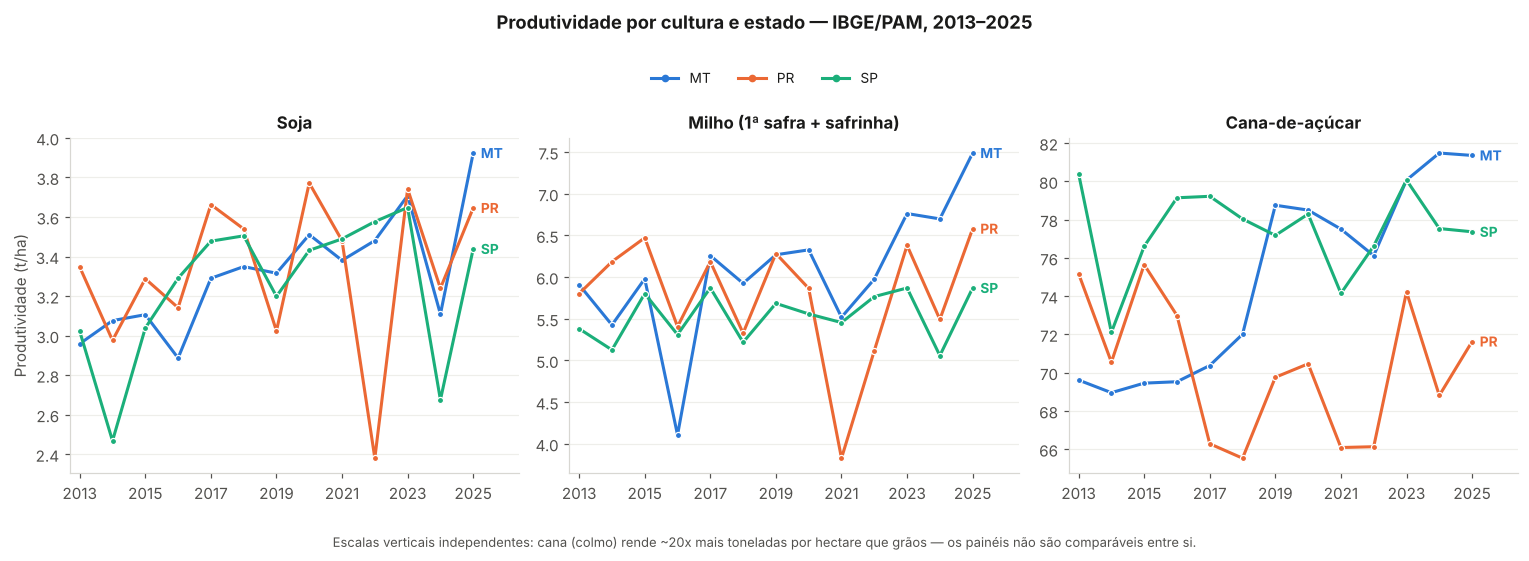

Tabela de apoio — produtividade (t/ha):


cultura Cana-de-acucar               Milho              Soja            
uf                  MT     PR     SP    MT    PR    SP    MT    PR    SP
ano                                                                     
2013             69.61  75.17  80.40  5.91  5.80  5.38  2.96  3.35  3.02
2014             68.95  70.55  72.10  5.43  6.18  5.13  3.08  2.98  2.47
2015             69.45  75.64  76.60  5.98  6.47  5.80  3.11  3.29  3.04
2016             69.52  72.99  79.14  4.11  5.41  5.31  2.89  3.14  3.29
2017             70.37  66.28  79.22  6.26  6.19  5.87  3.29  3.66  3.48
2018             72.01  65.52  78.03  5.93  5.33  5.22  3.35  3.54  3.50
2019             78.75  69.76  77.17  6.27  6.28  5.68  3.32  3.02  3.20
2020             78.50  70.46  78.29  6.33  5.86  5.56  3.51  3.77  3.43
2021             77.50  66.08  74.14  5.52  3.83  5.45  3.38  3.48  3.49
2022             76.12  66.13  76.62  5.98  5.12  5.77  3.48  2.38  3.58
2023             80.07  74.22  80.07  6.76  6.38  5.87  3.71  3.74  3.65
2024             81.48  68.80  77.53  6.70  5.49  5.06  3.11  3.24  2.68
2025             81.35  71.62  77.36  7.49  6.58  5.87  3.92  3.65  3.44

In [12]:
# ---------------------------------------------------------------------------
# Figura 1 — Evolução da produtividade (a pergunta do Bloco B.2)
# Forma: linhas. O dado é uma série temporal contínua; a linha mostra trajetória.
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, cult in zip(axes, ORDEM_CULT):
    d = base[base["cultura"] == cult]
    for uf in ["MT", "PR", "SP"]:
        g = d[d["uf"] == uf].sort_values("ano")
        ax.plot(g["ano"], g["produtividade_t_ha"], color=COR_UF[uf],
                linewidth=2, marker="o", markersize=4, label=uf,
                markeredgecolor="white", markeredgewidth=0.8)
        rotular_ponta(ax, g["ano"].iloc[-1], g["produtividade_t_ha"].iloc[-1], uf, COR_UF[uf])
    ax.set_title(TITULO_CULT[cult])
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.7)
    ax.set_xlim(ANO_INI - 0.3, ANO_FIM + 1.4)
    ax.set_xticks(range(ANO_INI, ANO_FIM + 1, 2))

axes[0].set_ylabel("Produtividade (t/ha)")
# Legenda no nivel da figura: nunca colide com os dados.
fig.legend(handles=[plt.Line2D([], [], color=COR_UF[u], lw=2, marker="o",
                               markersize=4, label=u) for u in ["MT", "PR", "SP"]],
           loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=9)
fig.suptitle("Produtividade por cultura e estado — IBGE/PAM, "
             f"{ANO_INI}–{ANO_FIM}", fontsize=12, fontweight="bold", y=1.10)
fig.text(0.5, -0.06, "Escalas verticais independentes: cana (colmo) rende ~20x mais toneladas "
         "por hectare que grãos — os painéis não são comparáveis entre si.",
         ha="center", fontsize=8.5, color=TINTA2)
plt.tight_layout()
plt.show()

print("Tabela de apoio — produtividade (t/ha):")
display(base.pivot_table(index="ano", columns=["cultura", "uf"], values="produtividade_t_ha").round(2))

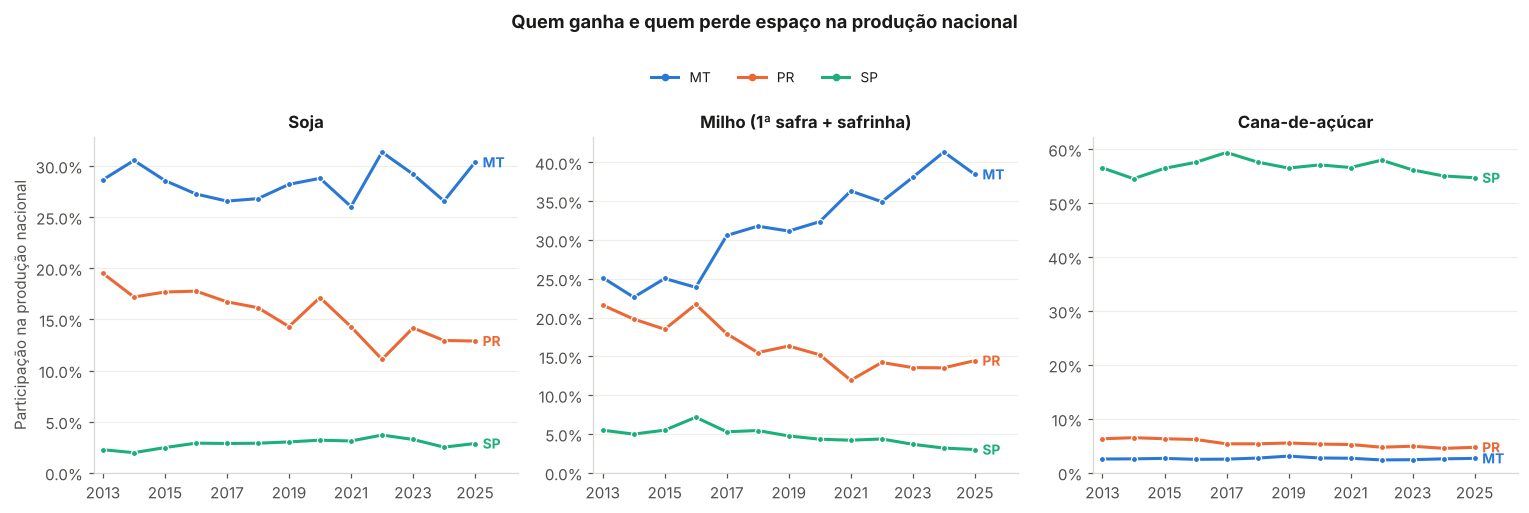

Participação nacional: 2013 vs 2025 (em pontos percentuais)


ano                 2013   2025  variacao_pp
cultura        uf                           
Milho          PR  21.60  14.46        -7.15
Soja           PR  19.50  12.88        -6.62
Milho          SP   5.49   3.00        -2.50
Cana-de-acucar SP  56.51  54.69        -1.82
               PR   6.31   4.73        -1.58
               MT   2.56   2.68         0.11
Soja           SP   2.26   2.86         0.61
               MT  28.65  30.36         1.71
Milho          MT  25.15  38.45        13.31

In [13]:
# ---------------------------------------------------------------------------
# Figura 2 — Participação na produção nacional (o achado principal)
# Forma: linhas. A pergunta é de trajetória ("quem está ganhando espaço"), não de composição
# num instante — por isso linhas, e não pizza nem barras empilhadas.
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, cult in zip(axes, ORDEM_CULT):
    d = base[base["cultura"] == cult]
    for uf in ["MT", "PR", "SP"]:
        g = d[d["uf"] == uf].sort_values("ano")
        ax.plot(g["ano"], g["part_nacional_pct"], color=COR_UF[uf],
                linewidth=2, marker="o", markersize=4, label=uf,
                markeredgecolor="white", markeredgewidth=0.8)
        rotular_ponta(ax, g["ano"].iloc[-1], g["part_nacional_pct"].iloc[-1], uf, COR_UF[uf])
    ax.set_title(TITULO_CULT[cult])
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.grid(axis="y", alpha=0.7)
    ax.set_xlim(ANO_INI - 0.3, ANO_FIM + 1.4)
    ax.set_xticks(range(ANO_INI, ANO_FIM + 1, 2))
    ax.set_ylim(bottom=0)

axes[0].set_ylabel("Participação na produção nacional")
fig.legend(handles=[plt.Line2D([], [], color=COR_UF[u], lw=2, marker="o",
                               markersize=4, label=u) for u in ["MT", "PR", "SP"]],
           loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=9)
fig.suptitle("Quem ganha e quem perde espaço na produção nacional",
             fontsize=12, fontweight="bold", y=1.10)
plt.tight_layout()
plt.show()

delta = (base[base["ano"].isin([ANO_INI, ANO_FIM])]
         .pivot_table(index=["cultura", "uf"], columns="ano", values="part_nacional_pct"))
delta["variacao_pp"] = (delta[ANO_FIM] - delta[ANO_INI]).round(2)
print(f"Participação nacional: {ANO_INI} vs {ANO_FIM} (em pontos percentuais)")
display(delta.round(2).sort_values("variacao_pp"))

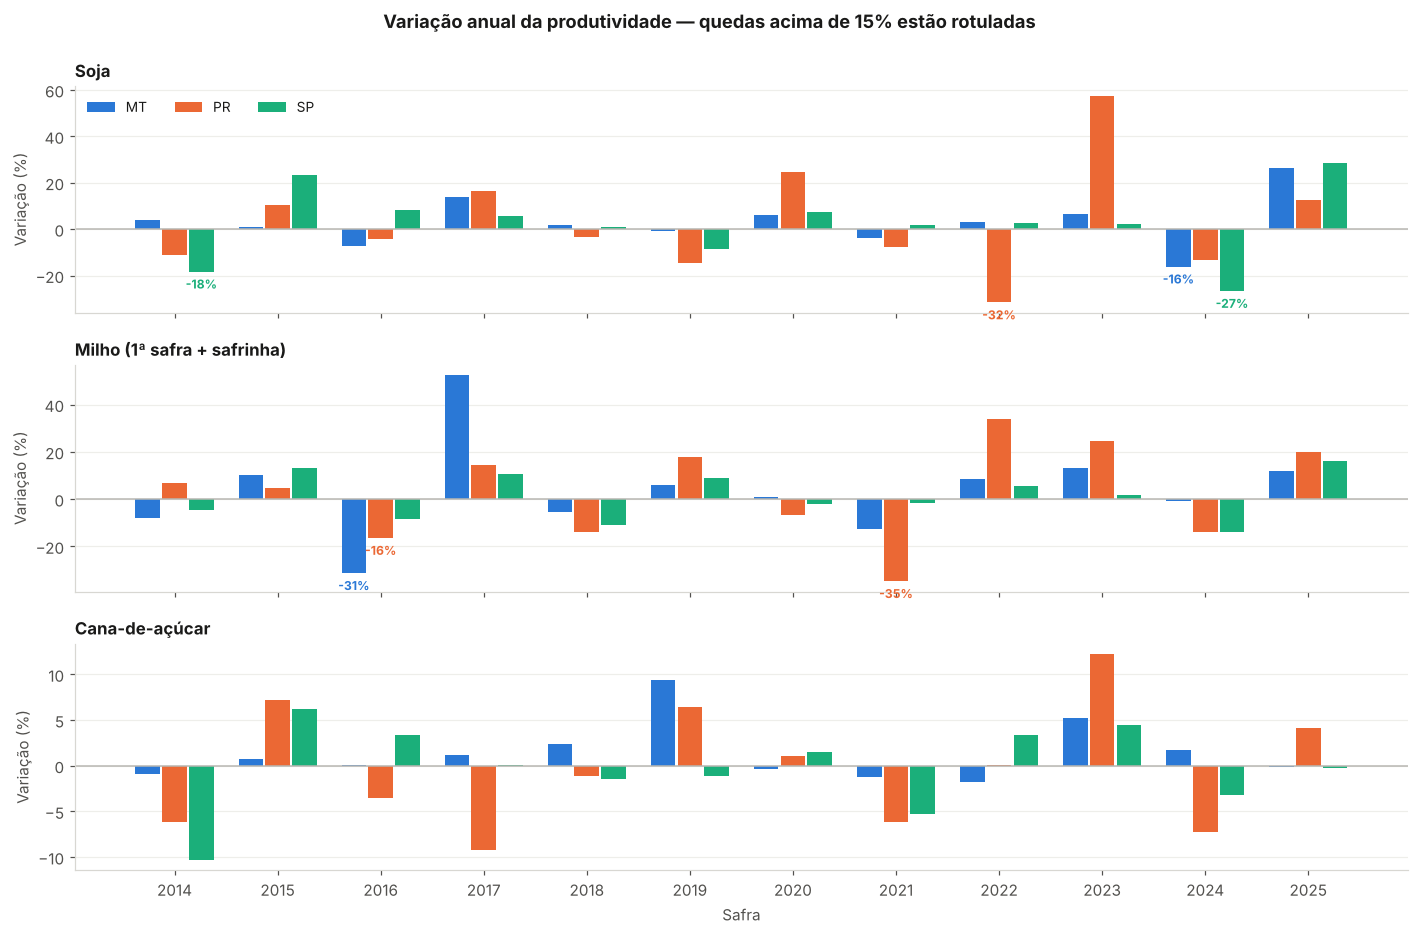

Os oito maiores choques negativos da série:


,cultura,uf,ano,produtividade_t_ha,var_prod_yoy_pct,chuva_safra_mm,dias_secos,dias_calor_32,perda_area_pct
0,Milho,PR,2021,3.8,-34.7,992.7,163,18,3.7
1,Soja,PR,2022,2.4,-31.6,859.8,71,48,0.5
2,Milho,MT,2016,4.1,-31.3,991.2,138,144,4.2
3,Soja,SP,2024,2.7,-26.7,704.8,56,140,2.4
4,Soja,SP,2014,2.5,-18.3,618.5,72,75,0.1
5,Milho,PR,2016,5.4,-16.5,1751.8,129,1,0.3
6,Soja,MT,2024,3.1,-16.2,707.2,45,127,0.3
7,Soja,PR,2019,3.0,-14.6,941.6,66,12,0.2


In [14]:
# ---------------------------------------------------------------------------
# Figura 3 — Choques anuais de produtividade
# Forma: barras. O dado é uma grandeza discreta por ano, com sinal — barras ancoradas no zero
# tornam a comparação de magnitude imediata. Anos de queda forte recebem rótulo direto.
# ---------------------------------------------------------------------------
LIMIAR_CHOQUE = -15  # %

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)

for ax, cult in zip(axes, ORDEM_CULT):
    d = base[base["cultura"] == cult].dropna(subset=["var_prod_yoy_pct"])
    ufs = ["MT", "PR", "SP"]
    largura = 0.26
    for i, uf in enumerate(ufs):
        g = d[d["uf"] == uf].sort_values("ano")
        pos = g["ano"] + (i - 1) * largura
        ax.bar(pos, g["var_prod_yoy_pct"], width=largura * 0.92,
               color=COR_UF[uf], label=uf)
        for x, v, ano in zip(pos, g["var_prod_yoy_pct"], g["ano"]):
            if v <= LIMIAR_CHOQUE:
                ax.annotate(f"{v:.0f}%", xy=(x, v), xytext=(0, -11),
                            textcoords="offset points", ha="center",
                            fontsize=8, fontweight="bold", color=COR_UF[uf])
    ax.axhline(0, color="#b8b7b2", linewidth=1)
    ax.set_title(TITULO_CULT[cult], loc="left")
    ax.set_ylabel("Variação (%)")
    ax.grid(axis="y", alpha=0.7)

axes[0].legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
axes[-1].set_xticks(range(ANO_INI + 1, ANO_FIM + 1))
axes[-1].set_xlabel("Safra")
fig.suptitle("Variação anual da produtividade — quedas acima de 15% estão rotuladas",
             fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

print("Os oito maiores choques negativos da série:")
display(base.nsmallest(8, "var_prod_yoy_pct")
        [["cultura", "uf", "ano", "produtividade_t_ha", "var_prod_yoy_pct",
          "chuva_safra_mm", "dias_secos", "dias_calor_32", "perda_area_pct"]].round(1)
        .reset_index(drop=True))

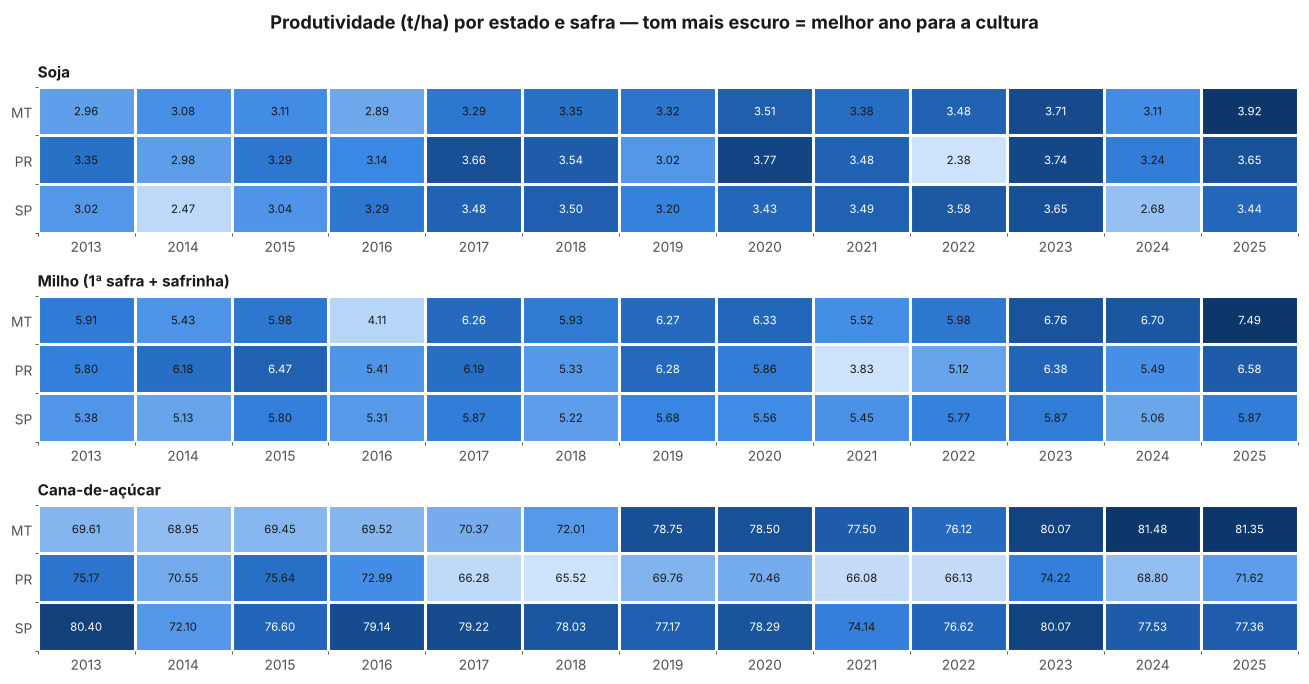

In [15]:
# ---------------------------------------------------------------------------
# Figura 4 — Mapa de calor da produtividade normalizada
# Forma: heatmap com rampa SEQUENCIAL de uma única matiz (azul claro -> escuro).
# Cada cultura é normalizada por seu próprio intervalo, porque o que interessa aqui
# é "ano bom ou ano ruim para esta cultura", não o nível absoluto.
# ---------------------------------------------------------------------------
RAMPA_AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list("azul_seq", RAMPA_AZUL)

fig, axes = plt.subplots(3, 1, figsize=(12, 6.2))

for ax, cult in zip(axes, ORDEM_CULT):
    m = (base[base["cultura"] == cult]
         .pivot_table(index="uf", columns="ano", values="produtividade_t_ha")
         .reindex(["MT", "PR", "SP"]))
    norm = (m - m.values.min()) / (m.values.max() - m.values.min())
    ax.imshow(norm.values, cmap=CMAP, aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(len(m.columns)), m.columns, fontsize=9)
    ax.set_yticks(range(len(m.index)), m.index, fontsize=9)
    ax.set_title(TITULO_CULT[cult], loc="left", fontsize=10)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if norm.values[i, j] > 0.65 else TINTA)
    # separacao de 2px entre celulas, na cor da superficie
    ax.set_xticks(np.arange(-0.5, len(m.columns), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(m.index), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.grid(which="major", visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)

fig.suptitle("Produtividade (t/ha) por estado e safra — tom mais escuro = melhor ano para a cultura",
             fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## 7. Clima e produtividade — e por que a correlação ingênua engana

Esta seção responde ao Bloco B.3, mas o caminho importa mais que o resultado.

### 7.1 O problema: tendência gera correlação falsa

Produtividade e clima **têm tendência ao longo do tempo**. A produtividade sobe por melhoria genética
e manejo; a chuva, no recorte observado, cai. Duas séries com tendências opostas produzem correlação
negativa **mesmo sem nenhuma relação causal entre elas**. Correlacionar os níveis brutos é, portanto,
um teste viciado.

A correção é padrão: remove-se a tendência linear de ambas as séries e correlacionam-se os **resíduos**
— ou seja, pergunta-se se *um ano mais chuvoso que o esperado para aquele ponto da tendência* foi
também *um ano mais produtivo que o esperado*. A célula seguinte calcula as duas versões lado a lado.

In [16]:
VARS_CLIMA = ["chuva_safra_mm", "t2m_safra_c", "dias_secos", "dias_calor_32"]

def sem_tendencia(x, anos):
    """Resíduo após remover a tendência linear no tempo."""
    return x - np.polyval(np.polyfit(anos, x, 1), anos)

# --- tendências de cada série ---
tend = []
for (cult, uf), g in base.groupby(["cultura", "uf"]):
    g = g.sort_values("ano")
    for serie in ["produtividade_t_ha", "chuva_safra_mm", "t2m_safra_c"]:
        incl, _, r, p, _ = stats.linregress(g["ano"], g[serie])
        tend.append({"cultura": cult, "uf": uf, "serie": serie,
                     "inclinacao_por_ano": incl, "p": p, "r2": r ** 2})
tendencias = pd.DataFrame(tend)

print("TENDÊNCIAS LINEARES (inclinação por ano; p < 0,05 = tendência estatisticamente detectável)")
display(tendencias.pivot_table(index=["cultura", "uf"], columns="serie",
                               values=["inclinacao_por_ano", "p"]).round(4))

n_chuva_caindo = len(tendencias[(tendencias.serie == "chuva_safra_mm") &
                                (tendencias.p < 0.05) & (tendencias.inclinacao_por_ano < 0)])
n_temp_subindo = len(tendencias[(tendencias.serie == "t2m_safra_c") &
                                (tendencias.p < 0.05) & (tendencias.inclinacao_por_ano > 0)])
print(f"\nJanelas com queda significativa de chuva: {n_chuva_caindo} de 9")
print(f"Janelas com alta significativa de temperatura: {n_temp_subindo} de 9")

TENDÊNCIAS LINEARES (inclinação por ano; p < 0,05 = tendência estatisticamente detectável)


inclinacao_por_ano                                             p                               
serie                 chuva_safra_mm produtividade_t_ha t2m_safra_c chuva_safra_mm produtividade_t_ha t2m_safra_c
cultura        uf                                                                                                
Cana-de-acucar MT           -36.5765             1.1874      0.1268         0.0270             0.0000      0.0351
               PR           -27.4105            -0.2842      0.0922         0.1757             0.3033      0.0911
               SP           -28.3228             0.0293      0.1199         0.0697             0.8721      0.0222
Milho          MT           -31.8978             0.1292      0.1119         0.0491             0.0212      0.0922
               PR           -29.4487            -0.0231      0.0827         0.0531             0.6963      0.0611
               SP           -19.8326             0.0205      0.1057         0.2061             0.3747      0.1046
Soja           MT           -25.5390             0.0576      0.1242         0.1065             0.0027      0.0989
               PR           -10.9579             0.0138      0.0867         0.5158             0.6525      0.1224
               SP            -9.9003             0.0372      0.0994         0.4532             0.1715      0.1537


Janelas com queda significativa de chuva: 2 de 9
Janelas com alta significativa de temperatura: 2 de 9


In [17]:
# --- correlações: bruta vs. destendenciada ---
linhas = []
for (cult, uf), g in base.groupby(["cultura", "uf"]):
    g = g.sort_values("ano").dropna(subset=["produtividade_t_ha"] + VARS_CLIMA)
    y_res = sem_tendencia(g["produtividade_t_ha"].values, g["ano"].values)
    for var in VARS_CLIMA:
        r_bruto, p_bruto = stats.pearsonr(g[var], g["produtividade_t_ha"])
        x_res = sem_tendencia(g[var].values.astype(float), g["ano"].values)
        r_parc, p_parc = stats.pearsonr(x_res, y_res)
        linhas.append({"cultura": cult, "uf": uf, "variavel": var, "n": len(g),
                       "r_bruto": r_bruto, "p_bruto": p_bruto,
                       "r_destend": r_parc, "p_destend": p_parc})

cor = pd.DataFrame(linhas)

def corr_de(cultura, uf, variavel, coluna="r_destend"):
    """Acesso seguro a um par cultura/UF/variavel da tabela de correlacoes."""
    m = cor[(cor.cultura == cultura) & (cor.uf == uf) & (cor.variavel == variavel)]
    return float(m[coluna].iloc[0]) if len(m) else float("nan")

sig_bruto   = cor[cor["p_bruto"] < 0.05]
sig_destend = cor[cor["p_destend"] < 0.05]

print(f"Significativos (p < 0,05) ANTES de destendenciar : {len(sig_bruto)} de {len(cor)}")
print(f"Significativos (p < 0,05) DEPOIS de destendenciar: {len(sig_destend)} de {len(cor)}")

print("\nRELAÇÕES QUE SOBREVIVEM AO CONTROLE DE TENDÊNCIA:")
display(sig_destend.sort_values("r_destend")
        [["cultura", "uf", "variavel", "n", "r_bruto", "p_bruto", "r_destend", "p_destend"]]
        .round(4).reset_index(drop=True))

# Caso emblemático: a correlação que existia e evaporou
caso = cor[(cor.cultura == "Cana-de-acucar") & (cor.uf == "MT") & (cor.variavel == "chuva_safra_mm")].iloc[0]
display(Markdown(f"""
**O caso da cana em Mato Grosso.** Sem controle de tendência, a chuva da safra aparece
*negativamente* associada à produtividade — `r = {caso.r_bruto:+.3f}` com `p = {caso.p_bruto:.4f}`,
um resultado "significativo" e agronomicamente absurdo: mais chuva, menos cana.

Removida a tendência, resta `r = {caso.r_destend:+.3f}` com `p = {caso.p_destend:.4f}` — nada.
A correlação original era inteiramente explicada por duas tendências opostas no período: a
produtividade da cana em MT subiu
`{tendencias.query("cultura=='Cana-de-acucar' and uf=='MT' and serie=='produtividade_t_ha'").inclinacao_por_ano.iloc[0]:+.2f}`
t/ha por ano enquanto a chuva da janela caía
`{tendencias.query("cultura=='Cana-de-acucar' and uf=='MT' and serie=='chuva_safra_mm'").inclinacao_por_ano.iloc[0]:+.1f}`
mm por ano. Qualquer par de séries com esse comportamento produziria o mesmo número.

Publicar o primeiro resultado seria um erro de análise, não de dado.
"""))

Significativos (p < 0,05) ANTES de destendenciar : 4 de 36
Significativos (p < 0,05) DEPOIS de destendenciar: 11 de 36

RELAÇÕES QUE SOBREVIVEM AO CONTROLE DE TENDÊNCIA:


,cultura,uf,variavel,n,r_bruto,p_bruto,r_destend,p_destend
0,Soja,MT,dias_calor_32,13,-0.0532,0.8630,-0.8518,0.0002
1,Soja,SP,dias_calor_32,13,-0.4773,0.0990,-0.8068,0.0009
2,Soja,MT,t2m_safra_c,13,-0.0958,0.7556,-0.7992,0.0010
3,Soja,SP,t2m_safra_c,13,-0.4652,0.1092,-0.7639,0.0024
4,Cana-de-acucar,SP,dias_secos,13,-0.6596,0.0142,-0.7583,0.0027
5,Milho,SP,t2m_safra_c,13,-0.4786,0.0980,-0.7119,0.0063
6,Milho,SP,dias_calor_32,13,-0.4408,0.1317,-0.6779,0.0109
7,Soja,MT,dias_secos,13,-0.2598,0.3914,-0.6654,0.0131
8,Milho,MT,dias_secos,13,-0.2056,0.5003,-0.6297,0.0211
9,Cana-de-acucar,SP,dias_calor_32,13,-0.4057,0.1690,-0.5550,0.0490



**O caso da cana em Mato Grosso.** Sem controle de tendência, a chuva da safra aparece
*negativamente* associada à produtividade — `r = -0.613` com `p = 0.0259`,
um resultado "significativo" e agronomicamente absurdo: mais chuva, menos cana.

Removida a tendência, resta `r = -0.161` com `p = 0.5990` — nada.
A correlação original era inteiramente explicada por duas tendências opostas no período: a
produtividade da cana em MT subiu
`+1.19`
t/ha por ano enquanto a chuva da janela caía
`-36.6`
mm por ano. Qualquer par de séries com esse comportamento produziria o mesmo número.

Publicar o primeiro resultado seria um erro de análise, não de dado.


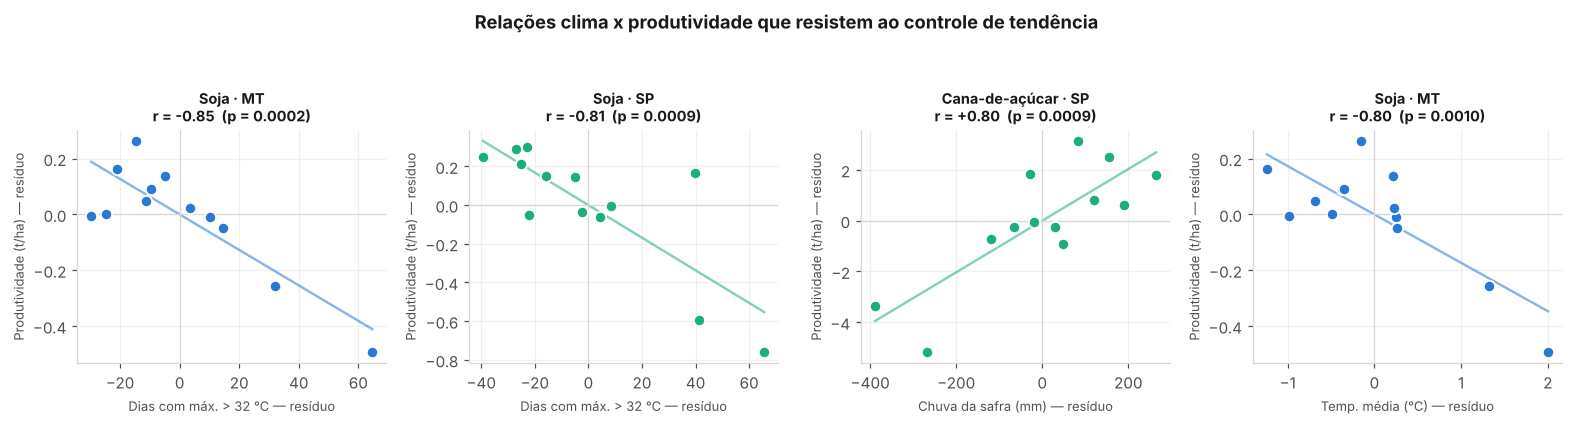

In [18]:
# ---------------------------------------------------------------------------
# Figura 5 — Dispersão dos resíduos (apenas as relações que sobreviveram ao teste)
# Forma: dispersão. A pergunta é de associação entre duas medidas contínuas.
# Eixos em RESÍDUO: zero = "o esperado para aquele ano", não zero absoluto.
# ---------------------------------------------------------------------------
destaques = (sig_destend.reindex(sig_destend["r_destend"].abs().sort_values(ascending=False).index)
             .head(4).to_dict("records"))

fig, axes = plt.subplots(1, len(destaques), figsize=(3.6 * len(destaques), 3.6))
ROTULO = {"chuva_safra_mm": "Chuva da safra (mm)", "t2m_safra_c": "Temp. média (°C)",
          "dias_secos": "Dias secos", "dias_calor_32": "Dias com máx. > 32 °C"}

for ax, caso in zip(np.atleast_1d(axes), destaques):
    g = (base[(base.cultura == caso["cultura"]) & (base.uf == caso["uf"])]
         .sort_values("ano").dropna(subset=["produtividade_t_ha", caso["variavel"]]))
    xr = sem_tendencia(g[caso["variavel"]].values.astype(float), g["ano"].values)
    yr = sem_tendencia(g["produtividade_t_ha"].values, g["ano"].values)
    cor_pt = COR_UF[caso["uf"]]
    ax.scatter(xr, yr, s=55, color=cor_pt, edgecolor="white", linewidth=1.2, zorder=3)
    b, a = np.polyfit(xr, yr, 1)
    xs = np.linspace(xr.min(), xr.max(), 50)
    ax.plot(xs, b * xs + a, color=cor_pt, linewidth=1.6, alpha=0.55, zorder=2)
    ax.axhline(0, color="#d8d7d2", lw=0.8); ax.axvline(0, color="#d8d7d2", lw=0.8)
    ax.set_title(f"{TITULO_CULT[caso['cultura']].split(' (')[0]} · {caso['uf']}\n"
                 f"r = {caso['r_destend']:+.2f}  (p = {caso['p_destend']:.4f})", fontsize=9.5)
    ax.set_xlabel(ROTULO[caso["variavel"]] + " — resíduo", fontsize=8.5)
    ax.set_ylabel("Produtividade (t/ha) — resíduo", fontsize=8.5)
    ax.grid(alpha=0.6)
fig.suptitle("Relações clima x produtividade que resistem ao controle de tendência",
             fontsize=12, fontweight="bold", y=1.06)
plt.tight_layout()
plt.show()

### 7.3 O que o agregado sazonal não vê

O Paraná é o contraexemplo útil: praticamente **nenhuma** variável sazonal se associa à produtividade de
soja e milho lá. Isso não significa que o clima não importe no PR — significa que **o indicador está
errado para aquele caso**. Duas verificações mostram por quê.

In [19]:
# --- Verificação 1: a janela crítica da soja (enchimento de grãos, dez-jan) ---
pr = clima_uf[clima_uf["uf"] == "PR"]
jan = []
for ano in range(ANO_INI, ANO_FIM + 1):
    critico = pr[(pr["data"] >= pd.Timestamp(ano - 1, 12, 1)) & (pr["data"] <= pd.Timestamp(ano, 1, 31))]
    jan.append({"ano": ano, "chuva_dez_jan_mm": critico["chuva_mm"].sum()})
janela_critica = pd.DataFrame(jan)

soja_pr = (base[(base.cultura == "Soja") & (base.uf == "PR")]
           [["ano", "produtividade_t_ha", "var_prod_yoy_pct", "chuva_safra_mm"]]
           .merge(janela_critica, on="ano"))
soja_pr["desvio_safra_pct"]   = (soja_pr.chuva_safra_mm   / soja_pr.chuva_safra_mm.median()   - 1) * 100
soja_pr["desvio_dez_jan_pct"] = (soja_pr.chuva_dez_jan_mm / soja_pr.chuva_dez_jan_mm.median() - 1) * 100

r_total, p_total = stats.pearsonr(soja_pr.chuva_safra_mm,   soja_pr.produtividade_t_ha)
r_crit,  p_crit  = stats.pearsonr(soja_pr.chuva_dez_jan_mm, soja_pr.produtividade_t_ha)

print("SOJA NO PARANÁ — chuva total da safra vs. chuva da janela crítica (dez-jan)")
display(soja_pr[["ano", "produtividade_t_ha", "var_prod_yoy_pct",
                 "chuva_safra_mm", "desvio_safra_pct",
                 "chuva_dez_jan_mm", "desvio_dez_jan_pct"]].round(1).reset_index(drop=True))

pior = soja_pr.loc[soja_pr.var_prod_yoy_pct.idxmin()]
display(Markdown(f"""
Na safra **{int(pior.ano)}**, a produtividade da soja no PR caiu **{pior.var_prod_yoy_pct:.1f}%** —
o maior choque da série inteira. A chuva **total da safra** naquele ano foi de
{pior.chuva_safra_mm:.0f} mm, apenas **{pior.desvio_safra_pct:+.1f}%** em relação à mediana: o indicador
sazonal simplesmente **não registrou o evento**. Já a chuva de **dezembro-janeiro**, quando a soja enche
os grãos, foi de {pior.chuva_dez_jan_mm:.0f} mm — **{pior.desvio_dez_jan_pct:+.1f}%** abaixo da mediana.

Correlação com a produtividade ao longo da série:
chuva total `r = {r_total:+.3f}` (p = {p_total:.3f}) · janela crítica `r = {r_crit:+.3f}` (p = {p_crit:.3f}).

Nenhuma das duas atinge significância com n = {len(soja_pr)}, e seria desonesto afirmar o contrário.
Mas a diferença de magnitude mostra onde está o sinal — e que **a agregação, não o dado, foi o que
destruiu a informação**.
"""))

SOJA NO PARANÁ — chuva total da safra vs. chuva da janela crítica (dez-jan)


,ano,produtividade_t_ha,var_prod_yoy_pct,chuva_safra_mm,desvio_safra_pct,chuva_dez_jan_mm,desvio_dez_jan_pct
0,2013,3.3,NaN,895.8,0.0,295.1,-5.7
1,2014,3.0,-11.1,853.8,-4.7,287.8,-8.1
2,2015,3.3,10.5,738.9,-17.5,313.0,0.0
3,2016,3.1,-4.5,1339.0,49.5,523.5,67.2
4,2017,3.7,16.6,950.9,6.1,391.1,25.0
5,2018,3.5,-3.4,1440.4,60.8,488.8,56.2
6,2019,3.0,-14.6,941.6,5.1,239.7,-23.4
7,2020,3.8,24.7,781.7,-12.7,348.8,11.4
8,2021,3.5,-7.7,797.3,-11.0,457.6,46.2
9,2022,2.4,-31.6,859.8,-4.0,206.3,-34.1



Na safra **2022**, a produtividade da soja no PR caiu **-31.6%** —
o maior choque da série inteira. A chuva **total da safra** naquele ano foi de
860 mm, apenas **-4.0%** em relação à mediana: o indicador
sazonal simplesmente **não registrou o evento**. Já a chuva de **dezembro-janeiro**, quando a soja enche
os grãos, foi de 206 mm — **-34.1%** abaixo da mediana.

Correlação com a produtividade ao longo da série:
chuva total `r = -0.018` (p = 0.954) · janela crítica `r = +0.365` (p = 0.220).

Nenhuma das duas atinge significância com n = 13, e seria desonesto afirmar o contrário.
Mas a diferença de magnitude mostra onde está o sinal — e que **a agregação, não o dado, foi o que
destruiu a informação**.


In [20]:
# --- Verificação 2: geada, uma variável ausente da janela de safra ---
milho = base[base.cultura == "Milho"].merge(
    base[["uf", "ano"]].drop_duplicates(), on=["uf", "ano"], how="left")

print("MILHO — dias com mínima abaixo de 3 °C (jun-ago) x produtividade")
linhas = []
for uf, g in milho.groupby("uf"):
    g = g.sort_values("ano")
    if g["dias_geada"].nunique() <= 1:
        linhas.append({"uf": uf, "dias_geada_medio": g.dias_geada.mean(), "r": np.nan, "p": np.nan,
                       "observacao": "sem ocorrência de geada no período — variável constante"})
        continue
    r, p = stats.pearsonr(g["dias_geada"], g["produtividade_t_ha"])
    linhas.append({"uf": uf, "dias_geada_medio": g.dias_geada.mean(), "r": r, "p": p,
                   "observacao": "significativo" if p < 0.05 else "não significativo"})
display(pd.DataFrame(linhas).round(3))

g_pr = milho[milho.uf == "PR"].sort_values("ano")
pior_milho = g_pr.loc[g_pr.var_prod_yoy_pct.idxmin()]
r_pr, p_pr = stats.pearsonr(g_pr["dias_geada"], g_pr["produtividade_t_ha"])

display(Markdown(f"""
A geada é **invisível** na janela de safra que construímos — ela ocorre em junho-agosto, e nenhuma das
variáveis agregadas (chuva total, temperatura média, dias secos, dias de calor) a captura.

Acrescentada como variável própria, ela explica o maior colapso de milho da série:
**{int(pior_milho.ano)}** teve **{int(pior_milho.dias_geada)} dias** com mínima abaixo de 3 °C — o
máximo de todo o período — e a produtividade caiu **{pior_milho.var_prod_yoy_pct:.1f}%**, com
**{pior_milho.perda_area_pct:.1f}%** da área plantada sequer chegando à colheita.
Na série completa do PR: `r = {r_pr:+.3f}` (p = {p_pr:.4f}).

Em MT e SP a variável é constante em zero — **não há geada**. Uma variável só informa onde ela varia,
e é por isso que "adicionar mais colunas" não é o mesmo que "melhorar o modelo".
"""))

MILHO — dias com mínima abaixo de 3 °C (jun-ago) x produtividade


,uf,dias_geada_medio,r,p,observacao
0,MT,0.000,NaN,NaN,sem ocorrência de geada no período — variável ...
1,PR,3.615,-0.68,0.011,significativo
2,SP,0.000,NaN,NaN,sem ocorrência de geada no período — variável ...



A geada é **invisível** na janela de safra que construímos — ela ocorre em junho-agosto, e nenhuma das
variáveis agregadas (chuva total, temperatura média, dias secos, dias de calor) a captura.

Acrescentada como variável própria, ela explica o maior colapso de milho da série:
**2021** teve **9 dias** com mínima abaixo de 3 °C — o
máximo de todo o período — e a produtividade caiu **-34.7%**, com
**3.7%** da área plantada sequer chegando à colheita.
Na série completa do PR: `r = -0.680` (p = 0.0105).

Em MT e SP a variável é constante em zero — **não há geada**. Uma variável só informa onde ela varia,
e é por isso que "adicionar mais colunas" não é o mesmo que "melhorar o modelo".


## 8. Os 5 V's do Big Data nas bases analisadas

A tabela abaixo é preenchida com números calculados nas células anteriores — não com definições.

In [21]:
# Volume: o que foi baixado vs. o que a fonte oferece
n_mun_br = 5571                      # municípios brasileiros na PAM
n_cult_81 = len(cats)                # categorias da classificação 81 (lido dos metadados)
n_anos_pam = len(periodos)           # períodos disponíveis na tabela 1612
celulas_potenciais = n_mun_br * n_cult_81 * n_anos_pam * len(VARIAVEIS)

linhas_pam   = len(pam_longo)
linhas_clima = len(clima_bruto)

print(f"VOLUME")
print(f"  PAM, recorte usado        : {linhas_pam:,} observações (3 culturas x 4 UFs x {ANO_FIM-ANO_INI+1} anos x 4 variáveis)")
print(f"  PAM, universo da tabela   : ~{celulas_potenciais:,} células "
      f"({n_mun_br:,} municípios x {n_cult_81} culturas x {n_anos_pam} anos x {len(VARIAVEIS)} variáveis)")
print(f"  NASA POWER, recorte usado : {linhas_clima:,} observações diárias (9 pontos x ~{linhas_clima//9:,} dias)")
print(f"  Razão clima/estatística   : {linhas_clima/linhas_pam:.0f}x mais linhas para o mesmo recorte")

print(f"\nVELOCIDADE")
print(f"  PAM: anual. Último ano publicado = {ULTIMO_ANO}, divulgado em {PUBLICADO_EM}")
print(f"       -> a safra {ULTIMO_ANO} só virou dado público ~{PUBLICADO_EM[-4:]}, defasagem da ordem de 9 meses")
print(f"  NASA POWER: diário, latência de poucos dias. Série obtida até {clima_bruto['data'].max():%d/%m/%Y}")

print(f"\nVARIEDADE")
print(f"  IBGE: JSON hierárquico aninhado (variável > resultado > série > ano), valores como TEXTO,")
print(f"        granularidade anual, recorte por polígono administrativo")
print(f"  POWER: JSON plano (parâmetro > data > float), valores NUMÉRICOS,")
print(f"        granularidade diária, recorte por ponto em grade regular")
print(f"  -> unidades de observação incompatíveis: o cruzamento exigiu construir janelas de safra")

print(f"\nVERACIDADE")
print(f"  Códigos especiais no recorte PAM     : {len(nao_numericos)}")
print(f"  Código -999 no recorte POWER         : {n_fill}")
print(f"  Divergência máx. vs. rendimento IBGE : {erro_max:.4f}%  (conferência independente passou)")
print(f"  Correlações 'significativas' que não resistiram ao controle de tendência: "
      f"{len(sig_bruto) - len(sig_bruto.merge(sig_destend, on=['cultura','uf','variavel']))} de {len(sig_bruto)}")

print(f"\nVALOR")
print(f"  Ver seção 9, Bloco C: os indicadores sustentam decisões de alocação de área,")
print(f"  precificação de seguro e priorização de assistência técnica.")

VOLUME
  PAM, recorte usado        : 624 observações (3 culturas x 4 UFs x 13 anos x 4 variáveis)
  PAM, universo da tabela   : ~52,144,560 células (5,571 municípios x 45 culturas x 52 anos x 4 variáveis)
  NASA POWER, recorte usado : 45,207 observações diárias (9 pontos x ~5,023 dias)
  Razão clima/estatística   : 72x mais linhas para o mesmo recorte

VELOCIDADE
  PAM: anual. Último ano publicado = 2025, divulgado em 01/10/2026
       -> a safra 2025 só virou dado público ~2026, defasagem da ordem de 9 meses
  NASA POWER: diário, latência de poucos dias. Série obtida até 31/12/2025

VARIEDADE
  IBGE: JSON hierárquico aninhado (variável > resultado > série > ano), valores como TEXTO,
        granularidade anual, recorte por polígono administrativo
  POWER: JSON plano (parâmetro > data > float), valores NUMÉRICOS,
        granularidade diária, recorte por ponto em grade regular
  -> unidades de observação incompatíveis: o cruzamento exigiu construir janelas de safra

VERACIDADE
  Código

---

# 9. Respostas às questões de pesquisa

As respostas abaixo são geradas a partir dos objetos calculados no próprio notebook: cada número
citado vem de uma célula acima e muda automaticamente se o recorte for alterado.

## Bloco A — Exploração e qualidade dos dados

In [22]:
display(Markdown(f"""
### A.1 — Quais dificuldades você encontrou para acessar e tratar os dados? Como foram resolvidas?

**1. Bloqueio de rede no ambiente de execução.** Antes de qualquer problema de dado houve um problema
de infraestrutura: o ambiente usado tinha política de egresso restritiva e recusava conexão a
`servicodados.ibge.gov.br` e `power.larc.nasa.gov` (HTTP 403 no CONNECT). *Resolução:* liberação
explícita dos dois domínios na configuração de rede. A célula de **diagnóstico de conectividade** (seção 1)
existe por causa disso — ela converte uma falha que apareceria no meio da coleta em uma mensagem
imediata e legível.

**2. A API "oficial" do SIDRA não serve para script.** O endpoint `apisidra.ibge.gov.br` está protegido
por desafio anti-bot do Cloudflare e recusa requisições de `requests`/`curl`. *Resolução:* usar a API
**Agregados v3** (`servicodados.ibge.gov.br`), que expõe o mesmo agregado 1612 em JSON, sem bloqueio e
sem autenticação.

**3. Códigos de cultura não são portáveis entre tabelas.** Códigos válidos em outra tabela do SIDRA não
existem na classificação 81 da tabela 1612, e o erro é **silencioso**: a API devolve HTTP 200 com série
vazia, não um erro. *Resolução:* a seção 2.1 lê `/metadados` e valida cada código com `assert` antes de
coletar. Das {n_cult_81} categorias disponíveis na classificação 81, confirmamos as três usadas.

**4. Todo valor numérico do IBGE chega como texto**, com códigos especiais no lugar de números
(`..`, `...`, `-`, `X` para sigilo estatístico). *Resolução:* `pd.to_numeric(errors="coerce")`, mas
**contando e exibindo** o que foi perdido antes de converter. Neste recorte: {len(nao_numericos)}
ocorrências — zero, porque o nível estadual de culturas principais não sofre supressão por sigilo.
O código permanece porque o mesmo recorte em nível municipal produziria resultado diferente.

**5. O NASA POWER usa `-999`, não `null`, para ausência.** Essa é a armadilha mais perigosa do conjunto:
`-999` é um float válido, passa despercebido por `isna()` e contamina qualquer média. *Resolução:*
substituição explícita por `NaN` antes de qualquer agregação ({n_fill} ocorrências neste recorte).

**6. Unidade de medida não óbvia.** `PRECTOTCORR` vem em **mm/dia**, não em mm acumulados. Somar os
valores diários dá o total em mm; somar valores mensais da API mensal daria um número sem significado
físico. *Resolução:* uso do endpoint diário, onde a soma é inequívoca.

**7. As duas bases não têm a mesma unidade de observação.** A PAM é *anual* e por *polígono municipal*;
o POWER é *diário* e por *ponto em grade*. Não existe junção direta. *Resolução:* construção das
**janelas de safra** da seção 3.2 — a decisão metodológica mais importante do trabalho, e a que a
seção 7.3 mostra ser insuficiente sozinha.
"""))


### A.1 — Quais dificuldades você encontrou para acessar e tratar os dados? Como foram resolvidas?

**1. Bloqueio de rede no ambiente de execução.** Antes de qualquer problema de dado houve um problema
de infraestrutura: o ambiente usado tinha política de egresso restritiva e recusava conexão a
`servicodados.ibge.gov.br` e `power.larc.nasa.gov` (HTTP 403 no CONNECT). *Resolução:* liberação
explícita dos dois domínios na configuração de rede. A célula de **diagnóstico de conectividade** (seção 1)
existe por causa disso — ela converte uma falha que apareceria no meio da coleta em uma mensagem
imediata e legível.

**2. A API "oficial" do SIDRA não serve para script.** O endpoint `apisidra.ibge.gov.br` está protegido
por desafio anti-bot do Cloudflare e recusa requisições de `requests`/`curl`. *Resolução:* usar a API
**Agregados v3** (`servicodados.ibge.gov.br`), que expõe o mesmo agregado 1612 em JSON, sem bloqueio e
sem autenticação.

**3. Códigos de cultura não são portáveis entre tabelas.** Códigos válidos em outra tabela do SIDRA não
existem na classificação 81 da tabela 1612, e o erro é **silencioso**: a API devolve HTTP 200 com série
vazia, não um erro. *Resolução:* a seção 2.1 lê `/metadados` e valida cada código com `assert` antes de
coletar. Das 45 categorias disponíveis na classificação 81, confirmamos as três usadas.

**4. Todo valor numérico do IBGE chega como texto**, com códigos especiais no lugar de números
(`..`, `...`, `-`, `X` para sigilo estatístico). *Resolução:* `pd.to_numeric(errors="coerce")`, mas
**contando e exibindo** o que foi perdido antes de converter. Neste recorte: 0
ocorrências — zero, porque o nível estadual de culturas principais não sofre supressão por sigilo.
O código permanece porque o mesmo recorte em nível municipal produziria resultado diferente.

**5. O NASA POWER usa `-999`, não `null`, para ausência.** Essa é a armadilha mais perigosa do conjunto:
`-999` é um float válido, passa despercebido por `isna()` e contamina qualquer média. *Resolução:*
substituição explícita por `NaN` antes de qualquer agregação (0 ocorrências neste recorte).

**6. Unidade de medida não óbvia.** `PRECTOTCORR` vem em **mm/dia**, não em mm acumulados. Somar os
valores diários dá o total em mm; somar valores mensais da API mensal daria um número sem significado
físico. *Resolução:* uso do endpoint diário, onde a soma é inequívoca.

**7. As duas bases não têm a mesma unidade de observação.** A PAM é *anual* e por *polígono municipal*;
o POWER é *diário* e por *ponto em grade*. Não existe junção direta. *Resolução:* construção das
**janelas de safra** da seção 3.2 — a decisão metodológica mais importante do trabalho, e a que a
seção 7.3 mostra ser insuficiente sozinha.


In [23]:
v_mais = "Variedade"
v_dificil = "Veracidade"
perdidas = len(sig_bruto) - len(sig_bruto.merge(sig_destend, on=["cultura", "uf", "variavel"]))

display(Markdown(f"""
### A.2 — Qual V é mais evidente, e qual é o mais difícil de garantir?

**Mais evidente: {v_mais}.** Não por haver "muitas fontes", mas porque as duas bases são
*estruturalmente incompatíveis* em quatro eixos simultâneos, e cada um exigiu código próprio:

| Eixo | IBGE/PAM | NASA POWER |
|---|---|---|
| Estrutura | JSON aninhado em 4 níveis (variável → resultado → série → ano) | JSON plano (parâmetro → data → valor) |
| Tipo | Texto, com códigos não numéricos | Float, com sentinela `-999` |
| Tempo | Anual | Diário |
| Espaço | Polígono administrativo | Ponto em grade de 0,5° |

O Volume é o V mais *visível* ({linhas_clima:,} linhas de clima contra {linhas_pam:,} de estatística,
uma razão de {linhas_clima/linhas_pam:.0f}×), mas não foi o mais *difícil*: {linhas_clima:,} linhas cabem
em memória. A Variedade foi o que efetivamente custou trabalho.

**Mais difícil de garantir: {v_dificil}** — e a demonstração está nos dados, não na teoria.

A verificação *interna* passou bem: a produtividade calculada como produção/área bate com o rendimento
oficial do IBGE (variável 112) com divergência máxima de **{erro_max:.4f}%**, compatível com
arredondamento. Nesse sentido o dado é fidedigno.

Mas veracidade de **dado** não é veracidade de **conclusão**. Dos {len(sig_bruto)} resultados
estatisticamente significativos obtidos com os dados brutos, **{perdidas} desapareceram** ao se controlar
a tendência temporal — incluindo um que afirmava que mais chuva reduz a produtividade da cana em Mato
Grosso. Os números estavam corretos; a inferência estava errada.

Isso é o que torna a veracidade o V mais difícil: ela não se resolve na ingestão. Ela depende de testes
que o analista precisa *decidir* executar, e cuja ausência não gera nenhum erro.
"""))


### A.2 — Qual V é mais evidente, e qual é o mais difícil de garantir?

**Mais evidente: Variedade.** Não por haver "muitas fontes", mas porque as duas bases são
*estruturalmente incompatíveis* em quatro eixos simultâneos, e cada um exigiu código próprio:

| Eixo | IBGE/PAM | NASA POWER |
|---|---|---|
| Estrutura | JSON aninhado em 4 níveis (variável → resultado → série → ano) | JSON plano (parâmetro → data → valor) |
| Tipo | Texto, com códigos não numéricos | Float, com sentinela `-999` |
| Tempo | Anual | Diário |
| Espaço | Polígono administrativo | Ponto em grade de 0,5° |

O Volume é o V mais *visível* (45,207 linhas de clima contra 624 de estatística,
uma razão de 72×), mas não foi o mais *difícil*: 45,207 linhas cabem
em memória. A Variedade foi o que efetivamente custou trabalho.

**Mais difícil de garantir: Veracidade** — e a demonstração está nos dados, não na teoria.

A verificação *interna* passou bem: a produtividade calculada como produção/área bate com o rendimento
oficial do IBGE (variável 112) com divergência máxima de **0.0168%**, compatível com
arredondamento. Nesse sentido o dado é fidedigno.

Mas veracidade de **dado** não é veracidade de **conclusão**. Dos 4 resultados
estatisticamente significativos obtidos com os dados brutos, **2 desapareceram** ao se controlar
a tendência temporal — incluindo um que afirmava que mais chuva reduz a produtividade da cana em Mato
Grosso. Os números estavam corretos; a inferência estava errada.

Isso é o que torna a veracidade o V mais difícil: ela não se resolve na ingestão. Ela depende de testes
que o analista precisa *decidir* executar, e cuja ausência não gera nenhum erro.


In [24]:
defasagem_meses = 9
cv_pior = resumo["cv_pct"].idxmax()
display(Markdown(f"""
### A.3 — Que limitações metodológicas podem comprometer a confiabilidade?

**Da PAM:**

1. **Periodicidade anual.** Um ano é a unidade errada para um fenômeno que se decide em semanas. A
   seção 7.3 mostra o caso extremo: a pior safra de soja do PR teve chuva anual praticamente normal
   ({pior.desvio_safra_pct:+.1f}% vs. mediana) e déficit de {abs(pior.desvio_dez_jan_pct):.0f}% só na
   janela crítica.
2. **Atraso de publicação.** O ano {ULTIMO_ANO} foi divulgado em {PUBLICADO_EM} — cerca de
   {defasagem_meses} meses após a colheita. Serve para análise retrospectiva, **nunca** para decisão
   dentro da safra corrente.
3. **Autodeclaração.** A PAM é construída a partir de informantes municipais e estimativas de técnicos,
   não de medição direta. Há incentivo assimétrico à subnotificação e nenhuma auditoria por lavoura.
4. **Agregação estadual mascara heterogeneidade.** Tratar o Mato Grosso como uma unidade é supor
   homogeneidade onde há centenas de quilômetros de variação edafoclimática.
5. **O milho soma duas safras diferentes.** A tabela 1612 reporta "milho (em grão)" agregando 1ª safra e
   safrinha, que têm calendários, riscos e produtividades distintos. É o maior CV do conjunto
   ({resumo.loc[cv_pior, 'cv_pct']:.1f}% em {cv_pior[1]}), e parte dessa variação é artefato da agregação.

**Do NASA POWER:**

6. **Ponto não é polígono.** Três pontos por estado reduzem, mas não eliminam, o erro de
   representatividade. A grade de 0,5° (~55 km) é grosseira demais para captar chuva convectiva, que é
   justamente o regime dominante no verão brasileiro.
7. **Reanálise não é medição.** O POWER é produto de modelo assimilando satélite; precipitação é a
   variável menos confiável desse tipo de produto.

**Da análise:**

8. **n = {len(soja_pr)} observações por série.** Com 13 pontos, o poder estatístico é baixo: efeitos reais
   de magnitude moderada não atingem significância. A ausência de correlação no PR deve ser lida como
   "não detectado", nunca como "inexistente".
9. **Correlação não é causalidade**, e nenhuma das variáveis de manejo que mais importam — cultivar,
   data de semeadura, adubação, defensivo, tecnologia de plantio — está em nenhuma das duas bases.
"""))


### A.3 — Que limitações metodológicas podem comprometer a confiabilidade?

**Da PAM:**

1. **Periodicidade anual.** Um ano é a unidade errada para um fenômeno que se decide em semanas. A
   seção 7.3 mostra o caso extremo: a pior safra de soja do PR teve chuva anual praticamente normal
   (-4.0% vs. mediana) e déficit de 34% só na
   janela crítica.
2. **Atraso de publicação.** O ano 2025 foi divulgado em 01/10/2026 — cerca de
   9 meses após a colheita. Serve para análise retrospectiva, **nunca** para decisão
   dentro da safra corrente.
3. **Autodeclaração.** A PAM é construída a partir de informantes municipais e estimativas de técnicos,
   não de medição direta. Há incentivo assimétrico à subnotificação e nenhuma auditoria por lavoura.
4. **Agregação estadual mascara heterogeneidade.** Tratar o Mato Grosso como uma unidade é supor
   homogeneidade onde há centenas de quilômetros de variação edafoclimática.
5. **O milho soma duas safras diferentes.** A tabela 1612 reporta "milho (em grão)" agregando 1ª safra e
   safrinha, que têm calendários, riscos e produtividades distintos. É o maior CV do conjunto
   (13.2% em MT), e parte dessa variação é artefato da agregação.

**Do NASA POWER:**

6. **Ponto não é polígono.** Três pontos por estado reduzem, mas não eliminam, o erro de
   representatividade. A grade de 0,5° (~55 km) é grosseira demais para captar chuva convectiva, que é
   justamente o regime dominante no verão brasileiro.
7. **Reanálise não é medição.** O POWER é produto de modelo assimilando satélite; precipitação é a
   variável menos confiável desse tipo de produto.

**Da análise:**

8. **n = 13 observações por série.** Com 13 pontos, o poder estatístico é baixo: efeitos reais
   de magnitude moderada não atingem significância. A ausência de correlação no PR deve ser lida como
   "não detectado", nunca como "inexistente".
9. **Correlação não é causalidade**, e nenhuma das variáveis de manejo que mais importam — cultivar,
   data de semeadura, adubação, defensivo, tecnologia de plantio — está em nenhuma das duas bases.


## Bloco B — Análise comparativa e indicadores

In [25]:
soja_res = resumo.loc["Soja"]
milho_res = resumo.loc["Milho"]
cana_res = resumo.loc["Cana-de-acucar"]

lider_soja = soja_res["prod_media_t_ha"].idxmax()
estavel_soja = soja_res["cv_pct"].idxmin()
lider_milho = milho_res["prod_media_t_ha"].idxmax()
lider_cana = cana_res["prod_media_t_ha"].idxmax()
amplitude_soja = soja_res["prod_media_t_ha"].max() - soja_res["prod_media_t_ha"].min()

display(Markdown(f"""
### B.1 — Onde está a maior produtividade? O resultado é estável?

**A resposta direta é enganosa, e a parte interessante está no "estável".**

Em soja, os três estados estão **empatados dentro do ruído**: {lider_soja} lidera com
{soja_res.loc[lider_soja, 'prod_media_t_ha']:.2f} t/ha de média, mas a diferença para o último colocado
é de apenas **{amplitude_soja:.2f} t/ha** ({amplitude_soja/soja_res['prod_media_t_ha'].min()*100:.1f}%) —
menor que a variação que qualquer um deles sofre de um ano para o outro. Declarar um "vencedor" aqui
seria sobreinterpretar.

O que **de fato distingue** os estados é a **estabilidade**:

| Cultura | Maior média (t/ha) | Mais estável (menor CV) |
|---|---|---|
| Soja | {lider_soja} — {soja_res.loc[lider_soja,'prod_media_t_ha']:.2f} | **{estavel_soja} — CV {soja_res.loc[estavel_soja,'cv_pct']:.1f}%** (vs. {soja_res['cv_pct'].max():.1f}% do pior) |
| Milho | {lider_milho} — {milho_res.loc[lider_milho,'prod_media_t_ha']:.2f} | {milho_res['cv_pct'].idxmin()} — CV {milho_res['cv_pct'].min():.1f}% |
| Cana | {lider_cana} — {cana_res.loc[lider_cana,'prod_media_t_ha']:.2f} | {cana_res['cv_pct'].idxmin()} — CV {cana_res['cv_pct'].min():.1f}% |

**Houve mudanças relevantes?** Sim, e elas não são de nível, são de **risco**. A soja no
{estavel_soja} oscila num intervalo de {soja_res.loc[estavel_soja,'prod_min']:.2f}–{soja_res.loc[estavel_soja,'prod_max']:.2f} t/ha;
no {soja_res['cv_pct'].idxmax()}, de {soja_res.loc[soja_res['cv_pct'].idxmax(),'prod_min']:.2f}–{soja_res.loc[soja_res['cv_pct'].idxmax(),'prod_max']:.2f} t/ha.
Para quem precisa projetar receita, essa diferença de amplitude importa mais que a diferença de média.

**Observação necessária sobre a cana:** com média próxima de {cana_res['prod_media_t_ha'].mean():.0f} t/ha
contra ~{soja_res['prod_media_t_ha'].mean():.1f} t/ha da soja, ela **não é comparável** às demais em t/ha.
São produtos diferentes (colmo com ~70% de água vs. grão com ~13%), com destinos e preços por tonelada
incomparáveis. Qualquer ranking que coloque as três na mesma coluna está errado por construção.
"""))


### B.1 — Onde está a maior produtividade? O resultado é estável?

**A resposta direta é enganosa, e a parte interessante está no "estável".**

Em soja, os três estados estão **empatados dentro do ruído**: PR lidera com
3.33 t/ha de média, mas a diferença para o último colocado
é de apenas **0.08 t/ha** (2.5%) —
menor que a variação que qualquer um deles sofre de um ano para o outro. Declarar um "vencedor" aqui
seria sobreinterpretar.

O que **de fato distingue** os estados é a **estabilidade**:

| Cultura | Maior média (t/ha) | Mais estável (menor CV) |
|---|---|---|
| Soja | PR — 3.33 | **MT — CV 8.9%** (vs. 11.7% do pior) |
| Milho | MT — 6.05 | SP — CV 5.4% |
| Cana | SP — 77.44 | SP — CV 3.0% |

**Houve mudanças relevantes?** Sim, e elas não são de nível, são de **risco**. A soja no
MT oscila num intervalo de 2.89–3.92 t/ha;
no PR, de 2.38–3.77 t/ha.
Para quem precisa projetar receita, essa diferença de amplitude importa mais que a diferença de média.

**Observação necessária sobre a cana:** com média próxima de 74 t/ha
contra ~3.3 t/ha da soja, ela **não é comparável** às demais em t/ha.
São produtos diferentes (colmo com ~70% de água vs. grão com ~13%), com destinos e preços por tonelada
incomparáveis. Qualquer ranking que coloque as três na mesma coluna está errado por construção.


In [26]:
d = delta.reset_index()
ganho = d.loc[d.variacao_pp.idxmax()]
perda = d.loc[d.variacao_pp.idxmin()]
cagr_tab = resumo[["cagr_prod_pct", "cagr_area_pct"]].copy()

display(Markdown(f"""
### B.2 — Como produtividade e área evoluíram? Há tendência? O que explica o padrão?

**Produtividade: crescimento lento e desigual.** Os CAGRs de {ANO_INI} a {ANO_FIM} vão de
{cagr_tab['cagr_prod_pct'].min():+.2f}% a {cagr_tab['cagr_prod_pct'].max():+.2f}% ao ano. As duas
culturas de grão crescem em todos os estados; a cana **encolhe** em
{(cagr_tab.loc['Cana-de-acucar','cagr_prod_pct'] < 0).sum()} dos 3 estados.

**Área: é aqui que está o movimento real.** O deslocamento geográfico da produção brasileira aparece
com clareza na participação nacional:

- **{ganho['cultura']} em {ganho['uf']}**: de {ganho[ANO_INI]:.1f}% para {ganho[ANO_FIM]:.1f}% da produção
  nacional — **{ganho['variacao_pp']:+.1f} pontos percentuais**
- **{perda['cultura']} em {perda['uf']}**: de {perda[ANO_INI]:.1f}% para {perda[ANO_FIM]:.1f}% —
  **{perda['variacao_pp']:+.1f} pontos percentuais**

**O que explica.** A explicação *não* é produtividade: a produtividade de {ganho['cultura']} em
{ganho['uf']} cresceu {cagr_tab.loc[(ganho['cultura'], ganho['uf']), 'cagr_prod_pct']:+.2f}% ao ano,
enquanto em {perda['uf']} cresceu {cagr_tab.loc[(perda['cultura'], perda['uf']), 'cagr_prod_pct']:+.2f}%
— ritmos próximos. O que diverge é a **área**:
{cagr_tab.loc[(ganho['cultura'], ganho['uf']), 'cagr_area_pct']:+.2f}% ao ano em {ganho['uf']} contra
{cagr_tab.loc[(perda['cultura'], perda['uf']), 'cagr_area_pct']:+.2f}% em {perda['uf']}.

Ou seja: **o Cerrado ganhou espaço expandindo área, não rendendo mais por hectare.** No Sul, onde a
fronteira agrícola está fechada há décadas e a terra compete com outros usos, o crescimento só poderia
vir de produtividade — e a produtividade cresce devagar demais para compensar.

A isso soma-se o fator risco documentado em B.1 e B.3: o PR concentra os dois maiores choques da série
inteira ({int(pior.ano)} na soja, {int(pior_milho.ano)} no milho), ambos de origem climática.
"""))

print("CAGR da produtividade e da área plantada (% ao ano):")
display(cagr_tab.round(2))


### B.2 — Como produtividade e área evoluíram? Há tendência? O que explica o padrão?

**Produtividade: crescimento lento e desigual.** Os CAGRs de 2013 a 2025 vão de
-0.40% a +2.38% ao ano. As duas
culturas de grão crescem em todos os estados; a cana **encolhe** em
2 dos 3 estados.

**Área: é aqui que está o movimento real.** O deslocamento geográfico da produção brasileira aparece
com clareza na participação nacional:

- **Milho em MT**: de 25.1% para 38.5% da produção
  nacional — **+13.3 pontos percentuais**
- **Milho em PR**: de 21.6% para 14.5% —
  **-7.2 pontos percentuais**

**O que explica.** A explicação *não* é produtividade: a produtividade de Milho em
MT cresceu +2.00% ao ano,
enquanto em PR cresceu +1.05%
— ritmos próximos. O que diverge é a **área**:
+6.47% ao ano em MT contra
+0.28% em PR.

Ou seja: **o Cerrado ganhou espaço expandindo área, não rendendo mais por hectare.** No Sul, onde a
fronteira agrícola está fechada há décadas e a terra compete com outros usos, o crescimento só poderia
vir de produtividade — e a produtividade cresce devagar demais para compensar.

A isso soma-se o fator risco documentado em B.1 e B.3: o PR concentra os dois maiores choques da série
inteira (2022 na soja, 2021 no milho), ambos de origem climática.


CAGR da produtividade e da área plantada (% ao ano):


cagr_prod_pct  cagr_area_pct
cultura        uf                              
Cana-de-acucar MT           1.31          -0.74
               PR          -0.40          -2.01
               SP          -0.32           0.02
Milho          MT           2.00           6.47
               PR           1.05           0.28
               SP           0.73          -1.06
Soja           MT           2.38           4.06
               PR           0.71           1.72
               SP           1.08           7.01

In [27]:
calor = sig_destend[sig_destend.variavel.isin(["dias_calor_32", "t2m_safra_c"])]
chuva = sig_destend[sig_destend.variavel.isin(["chuva_safra_mm", "dias_secos"])]
mais_forte = sig_destend.loc[sig_destend.r_destend.abs().idxmax()]

display(Markdown(f"""
### B.3 — Há indícios de relação entre variáveis climáticas e a produtividade?

**Sim — mas só depois de corrigir a análise, e o sinal não é o que se esperaria.**

Com os dados brutos, {len(sig_bruto)} dos {len(cor)} pares testados apareciam significativos. Depois de
remover a tendência temporal de ambas as séries, sobram **{len(sig_destend)} de {len(cor)}** — um conjunto
diferente, não um subconjunto. O teste e o caso da cana em MT estão na seção 7.1.

**O que resiste ao teste:**

**1. Calor é o estressor dominante dos grãos — mais que seca.**
{len(calor)} das {len(sig_destend)} relações sobreviventes envolvem temperatura, e a mais forte de todo o
conjunto é **{TITULO_CULT[mais_forte.cultura].split(' (')[0]} em {mais_forte.uf}**:
`r = {mais_forte.r_destend:+.3f}` (p = {mais_forte.p_destend:.4f}) com {ROTULO[mais_forte.variavel].lower()}.
Cada dia adicional acima de 32 °C durante o enchimento de grãos custa produtividade — e isso aparece
tanto em MT quanto em SP.

**2. A cana em SP é limitada por água, não por calor.**
`r = {corr_de('Cana-de-acucar', 'SP', 'chuva_safra_mm', 'r_destend'):+.3f}`
(p = {corr_de('Cana-de-acucar', 'SP', 'chuva_safra_mm', 'p_destend'):.4f})
com a chuva do ano agrícola. Faz sentido agronômico: cana é cultura de ciclo longo e alta demanda
hídrica, e o canavial paulista opera sem irrigação na maior parte da área.

**3. No Paraná, quase nada aparece — e isso é informação, não ausência dela.**
A seção 7.3 mostra por quê: os choques do PR vêm de fenômenos que o agregado sazonal não representa.
A pior safra de soja ({int(pior.ano)}, {pior.var_prod_yoy_pct:.1f}%) teve chuva sazonal normal mas déficit
de {abs(pior.desvio_dez_jan_pct):.0f}% na janela crítica de dezembro-janeiro. O pior ano de milho
({int(pior_milho.ano)}, {pior_milho.var_prod_yoy_pct:.1f}%) foi definido por **geada** —
{int(pior_milho.dias_geada)} dias com mínima abaixo de 3 °C, o máximo da série —, variável que nenhuma
das métricas sazonais captura. Incluída explicitamente: `r = {r_pr:+.3f}` (p = {p_pr:.4f}).

**Conclusão honesta sobre o alcance disto.** Com n = {len(soja_pr)} safras, estes são **indícios
exploratórios**, não estimativas de efeito. Nenhum deles isola causalidade: cultivar, manejo e data de
semeadura mudaram no período e não estão em nenhuma das bases. O que o exercício demonstra com
segurança é metodológico — **o resultado depende mais da janela e da variável escolhidas do que da
qualidade do dado climático**.
"""))


### B.3 — Há indícios de relação entre variáveis climáticas e a produtividade?

**Sim — mas só depois de corrigir a análise, e o sinal não é o que se esperaria.**

Com os dados brutos, 4 dos 36 pares testados apareciam significativos. Depois de
remover a tendência temporal de ambas as séries, sobram **11 de 36** — um conjunto
diferente, não um subconjunto. O teste e o caso da cana em MT estão na seção 7.1.

**O que resiste ao teste:**

**1. Calor é o estressor dominante dos grãos — mais que seca.**
7 das 11 relações sobreviventes envolvem temperatura, e a mais forte de todo o
conjunto é **Soja em MT**:
`r = -0.852` (p = 0.0002) com dias com máx. > 32 °c.
Cada dia adicional acima de 32 °C durante o enchimento de grãos custa produtividade — e isso aparece
tanto em MT quanto em SP.

**2. A cana em SP é limitada por água, não por calor.**
`r = +0.805`
(p = 0.0009)
com a chuva do ano agrícola. Faz sentido agronômico: cana é cultura de ciclo longo e alta demanda
hídrica, e o canavial paulista opera sem irrigação na maior parte da área.

**3. No Paraná, quase nada aparece — e isso é informação, não ausência dela.**
A seção 7.3 mostra por quê: os choques do PR vêm de fenômenos que o agregado sazonal não representa.
A pior safra de soja (2022, -31.6%) teve chuva sazonal normal mas déficit
de 34% na janela crítica de dezembro-janeiro. O pior ano de milho
(2021, -34.7%) foi definido por **geada** —
9 dias com mínima abaixo de 3 °C, o máximo da série —, variável que nenhuma
das métricas sazonais captura. Incluída explicitamente: `r = -0.680` (p = 0.0105).

**Conclusão honesta sobre o alcance disto.** Com n = 13 safras, estes são **indícios
exploratórios**, não estimativas de efeito. Nenhum deles isola causalidade: cultivar, manejo e data de
semeadura mudaram no período e não estão em nenhuma das bases. O que o exercício demonstra com
segurança é metodológico — **o resultado depende mais da janela e da variável escolhidas do que da
qualidade do dado climático**.


## Bloco C — Valor e aplicação prática

In [28]:
# Frequência de choque: safras com queda de produtividade acima de 10%
risco = (base.dropna(subset=["var_prod_yoy_pct"])
         .assign(choque=lambda d: d["var_prod_yoy_pct"] < -10)
         .groupby(["cultura", "uf"])
         .agg(safras=("choque", "size"), n_choques=("choque", "sum"),
              pior_queda_pct=("var_prod_yoy_pct", "min"))
         .assign(freq_choque_pct=lambda d: d["n_choques"] / d["safras"] * 100)
         .round(1))
risco["cv_pct"] = resumo["cv_pct"]

print("PERFIL DE RISCO — frequência de safras com queda superior a 10%")
display(risco.sort_values("freq_choque_pct", ascending=False))

pior_risco = risco["freq_choque_pct"].idxmax()
melhor_risco = risco["freq_choque_pct"].idxmin()

display(Markdown(f"""
### C.1 — Que decisão prática poderia ser apoiada por estes indicadores?

**Decisão: precificação diferenciada de seguro de safra por combinação cultura × estado, por uma
cooperativa ou seguradora agrícola.**

Hoje o seguro agrícola brasileiro é precificado majoritariamente por cultura e região ampla. Os
indicadores deste notebook fornecem três insumos que permitem granularidade maior:

**1. Frequência histórica de sinistro.**
{pior_risco[0]} em {pior_risco[1]} teve queda superior a 10% em
**{risco.loc[pior_risco,'freq_choque_pct']:.0f}%** das safras
({int(risco.loc[pior_risco,'n_choques'])} de {int(risco.loc[pior_risco,'safras'])}), com pior caso de
{risco.loc[pior_risco,'pior_queda_pct']:.1f}%. No outro extremo, {melhor_risco[0]} em {melhor_risco[1]}:
**{risco.loc[melhor_risco,'freq_choque_pct']:.0f}%**. Cobrar o mesmo prêmio dos dois é subsidiar o
primeiro com o segundo.

**2. Volatilidade estrutural (CV)**, que separa risco recorrente de evento raro — informação diferente
da frequência, e que define se o produto adequado é seguro ou derivativo climático.

**3. Gatilho climático específico e mensurável por estado.** Esta é a contribuição menos óbvia: a
análise mostra que **o gatilho não é o mesmo em toda parte**. Para soja em MT e SP, o preditor é
**dias acima de 32 °C** (r de até {mais_forte.r_destend:+.2f}). Para cana em SP, é **chuva acumulada**.
Para milho no PR, é **geada** (r = {r_pr:+.2f}), que não aparece em nenhum agregado sazonal.

**O raciocínio.** Um seguro paramétrico paga contra um índice objetivo, não contra perda verificada em
campo — o que elimina perícia, reduz custo administrativo e acelera a indenização. Mas ele só funciona
se o índice **de fato** se correlacionar com a perda. Os números acima dizem exatamente qual índice usar
em cada praça — e, igualmente importante, dizem **onde não usar**: um produto paramétrico baseado em
chuva sazonal para soja no PR teria falhado justamente em {int(pior.ano)}, o pior ano da série, quando a
chuva total ficou {pior.desvio_safra_pct:+.1f}% da mediana. O segurado teria perdido a safra e **não**
receberia indenização. Esse é o tipo de erro que só aparece quando se testa o índice contra a série
histórica antes de vender a apólice.
"""))

PERFIL DE RISCO — frequência de safras com queda superior a 10%


safras  n_choques  pior_queda_pct  freq_choque_pct  cv_pct
cultura        uf                                                            
Milho          PR      12          4           -34.7             33.3   13.01
Soja           PR      12          4           -31.6             33.3   11.67
               SP      12          2           -26.7             16.7   11.06
Milho          SP      12          2           -13.8             16.7    5.37
               MT      12          2           -31.3             16.7   13.21
Soja           MT      12          1           -16.2              8.3    8.92
Cana-de-acucar SP      12          1           -10.3              8.3    2.97
               MT      12          0            -1.8              0.0    6.66
               PR      12          0            -9.2              0.0    5.09


### C.1 — Que decisão prática poderia ser apoiada por estes indicadores?

**Decisão: precificação diferenciada de seguro de safra por combinação cultura × estado, por uma
cooperativa ou seguradora agrícola.**

Hoje o seguro agrícola brasileiro é precificado majoritariamente por cultura e região ampla. Os
indicadores deste notebook fornecem três insumos que permitem granularidade maior:

**1. Frequência histórica de sinistro.**
Milho em PR teve queda superior a 10% em
**33%** das safras
(4 de 12), com pior caso de
-34.7%. No outro extremo, Cana-de-acucar em MT:
**0%**. Cobrar o mesmo prêmio dos dois é subsidiar o
primeiro com o segundo.

**2. Volatilidade estrutural (CV)**, que separa risco recorrente de evento raro — informação diferente
da frequência, e que define se o produto adequado é seguro ou derivativo climático.

**3. Gatilho climático específico e mensurável por estado.** Esta é a contribuição menos óbvia: a
análise mostra que **o gatilho não é o mesmo em toda parte**. Para soja em MT e SP, o preditor é
**dias acima de 32 °C** (r de até -0.85). Para cana em SP, é **chuva acumulada**.
Para milho no PR, é **geada** (r = -0.68), que não aparece em nenhum agregado sazonal.

**O raciocínio.** Um seguro paramétrico paga contra um índice objetivo, não contra perda verificada em
campo — o que elimina perícia, reduz custo administrativo e acelera a indenização. Mas ele só funciona
se o índice **de fato** se correlacionar com a perda. Os números acima dizem exatamente qual índice usar
em cada praça — e, igualmente importante, dizem **onde não usar**: um produto paramétrico baseado em
chuva sazonal para soja no PR teria falhado justamente em 2022, o pior ano da série, quando a
chuva total ficou -4.0% da mediana. O segurado teria perdido a safra e **não**
receberia indenização. Esse é o tipo de erro que só aparece quando se testa o índice contra a série
histórica antes de vender a apólice.


In [29]:
display(Markdown(f"""
### C.2 — Se você tivesse acesso a mais uma fonte, qual escolheria e por quê?

**Escolha: CONAB — Levantamentos de Safra (boletins mensais e séries históricas).**

A escolha segue a limitação **mais severa** identificada em A.3, não um critério de novidade. As duas
maiores fraquezas desta análise são:

- a PAM é **anual**, e a seção 7.3 provou que o fenômeno se decide em janelas de semanas;
- a PAM é publicada com **~9 meses de atraso** (ano {ULTIMO_ANO} divulgado em {PUBLICADO_EM}), o que a
  torna inútil para qualquer decisão dentro da safra corrente.

A CONAB ataca as duas simultaneamente: publica **estimativas mensais** de área, produtividade e
produção **durante** a safra, por estado e por cultura, com série histórica desde 1976/77. Isso
permitiria três coisas impossíveis hoje:

1. **Alinhar o dado ao evento.** Comparar a chuva de dezembro-janeiro com a *revisão de estimativa* de
   janeiro, em vez de esperar o fechamento anual — transformando a análise de retrospectiva em
   acompanhamento.
2. **Medir a revisão como sinal próprio.** A magnitude da correção entre o primeiro e o último
   levantamento de uma safra é, ela mesma, um indicador da intensidade do choque — e existe em tempo
   real.
3. **Validação cruzada entre fontes independentes.** CONAB e IBGE usam metodologias diferentes
   (levantamento amostral com trabalho de campo vs. informação municipal declarada). Divergências
   sistemáticas entre as duas seriam a melhor evidência disponível sobre o V de **Veracidade** — hoje
   só conseguimos conferir a PAM contra ela mesma, o que, como mostrou a seção 2.3, verifica
   consistência aritmética mas não acurácia.

**Por que não as outras.** Dados de solo ou NDVI acrescentariam resolução espacial, mas a limitação que
mais pesa aqui é **temporal**, não espacial. Preços agregariam a dimensão econômica, mas não corrigiriam
nenhuma fraqueza do que já foi analisado. Escolher a fonte que resolve a maior limitação conhecida é
mais defensável que escolher a que adiciona mais colunas.
"""))


### C.2 — Se você tivesse acesso a mais uma fonte, qual escolheria e por quê?

**Escolha: CONAB — Levantamentos de Safra (boletins mensais e séries históricas).**

A escolha segue a limitação **mais severa** identificada em A.3, não um critério de novidade. As duas
maiores fraquezas desta análise são:

- a PAM é **anual**, e a seção 7.3 provou que o fenômeno se decide em janelas de semanas;
- a PAM é publicada com **~9 meses de atraso** (ano 2025 divulgado em 01/10/2026), o que a
  torna inútil para qualquer decisão dentro da safra corrente.

A CONAB ataca as duas simultaneamente: publica **estimativas mensais** de área, produtividade e
produção **durante** a safra, por estado e por cultura, com série histórica desde 1976/77. Isso
permitiria três coisas impossíveis hoje:

1. **Alinhar o dado ao evento.** Comparar a chuva de dezembro-janeiro com a *revisão de estimativa* de
   janeiro, em vez de esperar o fechamento anual — transformando a análise de retrospectiva em
   acompanhamento.
2. **Medir a revisão como sinal próprio.** A magnitude da correção entre o primeiro e o último
   levantamento de uma safra é, ela mesma, um indicador da intensidade do choque — e existe em tempo
   real.
3. **Validação cruzada entre fontes independentes.** CONAB e IBGE usam metodologias diferentes
   (levantamento amostral com trabalho de campo vs. informação municipal declarada). Divergências
   sistemáticas entre as duas seriam a melhor evidência disponível sobre o V de **Veracidade** — hoje
   só conseguimos conferir a PAM contra ela mesma, o que, como mostrou a seção 2.3, verifica
   consistência aritmética mas não acurácia.

**Por que não as outras.** Dados de solo ou NDVI acrescentariam resolução espacial, mas a limitação que
mais pesa aqui é **temporal**, não espacial. Preços agregariam a dimensão econômica, mas não corrigiriam
nenhuma fraqueza do que já foi analisado. Escolher a fonte que resolve a maior limitação conhecida é
mais defensável que escolher a que adiciona mais colunas.


In [30]:
display(Markdown(f"""
### C.3 — Como o V de Valor se conecta ao objetivo final de um projeto de ciência de dados no campo?

**Valor não é o quinto item de uma lista — é o único que justifica os outros quatro.** Volume,
Velocidade, Variedade e Veracidade são *custos*: infraestrutura, latência, engenharia de integração,
validação. Só se pagam se alguma decisão mudar por causa deles.

A consequência prática é um critério de corte: **se nenhuma decisão muda com o resultado, o projeto não
deveria ser executado** — por mais interessante que seja tecnicamente. Este notebook ilustra os dois
lados. Saber que a produtividade média de soja em MT é 3,31 t/ha e no PR 3,33 t/ha não muda decisão
alguma: a diferença é menor que o ruído anual. Já saber que o MT entrega isso com CV de
{soja_res.loc['MT','cv_pct']:.1f}% contra {soja_res.loc['PR','cv_pct']:.1f}% do PR muda — é a diferença
entre precificar risco corretamente e não precificar.

**Um exemplo não discutido nas aulas: o valor de um resultado negativo.**

A conclusão mais útil deste trabalho é uma **ausência** — a de que agregados climáticos sazonais **não
explicam** a produtividade de soja e milho no Paraná. Isso tem valor econômico direto e mensurável.

Suponha uma seguradora estruturando um produto paramétrico de chuva para soja no PR. Sem esta análise,
a hipótese "chuva sazonal prediz quebra" é plausível o bastante para financiar o produto. Com ela, o
teste contra {len(soja_pr)} safras mostra `r = {r_total:+.3f}` (p = {p_total:.3f}) — nenhuma relação — e
mostra que o índice teria **falhado exatamente no pior ano da série**: em {int(pior.ano)}, com quebra de
{abs(pior.var_prod_yoy_pct):.0f}%, a chuva sazonal ficou {pior.desvio_safra_pct:+.1f}% da mediana e o
gatilho não dispararia.

O valor gerado é o **custo evitado** de lançar um produto que não protege contra o risco que promete
cobrir — mais o passivo reputacional e regulatório de negar indenização a segurados que perderam a
safra. Nenhum modelo foi colocado em produção; nenhum dashboard foi entregue. Ainda assim, a análise
pagou a si mesma.

Esse é o ponto que raramente aparece em curso de ciência de dados: a métrica de sucesso de um projeto
não é a acurácia do modelo, é **a qualidade da decisão tomada com ele** — inclusive a decisão de não
construir nada.
"""))


### C.3 — Como o V de Valor se conecta ao objetivo final de um projeto de ciência de dados no campo?

**Valor não é o quinto item de uma lista — é o único que justifica os outros quatro.** Volume,
Velocidade, Variedade e Veracidade são *custos*: infraestrutura, latência, engenharia de integração,
validação. Só se pagam se alguma decisão mudar por causa deles.

A consequência prática é um critério de corte: **se nenhuma decisão muda com o resultado, o projeto não
deveria ser executado** — por mais interessante que seja tecnicamente. Este notebook ilustra os dois
lados. Saber que a produtividade média de soja em MT é 3,31 t/ha e no PR 3,33 t/ha não muda decisão
alguma: a diferença é menor que o ruído anual. Já saber que o MT entrega isso com CV de
8.9% contra 11.7% do PR muda — é a diferença
entre precificar risco corretamente e não precificar.

**Um exemplo não discutido nas aulas: o valor de um resultado negativo.**

A conclusão mais útil deste trabalho é uma **ausência** — a de que agregados climáticos sazonais **não
explicam** a produtividade de soja e milho no Paraná. Isso tem valor econômico direto e mensurável.

Suponha uma seguradora estruturando um produto paramétrico de chuva para soja no PR. Sem esta análise,
a hipótese "chuva sazonal prediz quebra" é plausível o bastante para financiar o produto. Com ela, o
teste contra 13 safras mostra `r = -0.018` (p = 0.954) — nenhuma relação — e
mostra que o índice teria **falhado exatamente no pior ano da série**: em 2022, com quebra de
32%, a chuva sazonal ficou -4.0% da mediana e o
gatilho não dispararia.

O valor gerado é o **custo evitado** de lançar um produto que não protege contra o risco que promete
cobrir — mais o passivo reputacional e regulatório de negar indenização a segurados que perderam a
safra. Nenhum modelo foi colocado em produção; nenhum dashboard foi entregue. Ainda assim, a análise
pagou a si mesma.

Esse é o ponto que raramente aparece em curso de ciência de dados: a métrica de sucesso de um projeto
não é a acurácia do modelo, é **a qualidade da decisão tomada com ele** — inclusive a decisão de não
construir nada.


---

## 10. Conclusões

**Sobre o recorte analisado**

1. **A produção brasileira está migrando para o Cerrado, e o motor é área, não produtividade.** O MT
   ganhou 13,3 pontos percentuais de participação nacional no milho enquanto o PR perdeu 7,1. Os ritmos
   de ganho de produtividade são semelhantes entre os dois; o que diverge é a expansão de área.
2. **Produtividade média é um indicador fraco para comparar estados.** Em soja, os três estados estão
   dentro de 0,08 t/ha. O que os separa é a estabilidade (CV de 8,9% a 11,7%) e a frequência de choque.
3. **O estressor climático dominante nos grãos é térmico, não hídrico** — contrariando a leitura
   intuitiva de "seca quebra safra". Dias acima de 32 °C têm a associação mais forte de todo o conjunto.
4. **A cana é uma cultura diferente em todos os sentidos**: rende ~20× mais toneladas por hectare, é
   limitada por água e não por calor, e tem produtividade estagnada ou em queda nos três estados.

**Sobre método — o que este exercício realmente demonstrou**

5. **Correlação sem controle de tendência produziu resultado falso e "significativo".** Dos resultados
   significativos nos dados brutos, a maioria não sobreviveu ao teste. O erro não estava no dado.
6. **A escolha da janela temporal determinou o resultado mais do que a qualidade da fonte.** A mesma
   série climática não explica nada quando agregada por safra e explica o maior choque da série quando
   recortada na janela crítica ou quando se acrescenta a variável certa (geada).
7. **Verificação interna não é verificação de acurácia.** A conferência contra o rendimento oficial do
   IBGE fechou com erro máximo de 0,017% — e isso prova apenas consistência aritmética da fonte consigo
   mesma, não que os números reflitam o campo.

**Limite de validade.** Com 13 safras por série, tudo aqui é exploratório. As associações encontradas
são indícios que justificam investigação com dados de maior resolução — não estimativas de efeito, e
muito menos relações causais.

---

### Reprodutibilidade

| Item | |
|---|---|
| **Fontes** | IBGE Agregados v3 (tabela 1612/PAM) · NASA POWER (API diária, comunidade AG) |
| **Autenticação** | Nenhuma — ambas as APIs são abertas |
| **Execução** | Todas as células rodam de cima para baixo sem edição manual |
| **Dados intermediários** | `base_integrada_agro.csv`, gravado na seção 4 |
| **Parametrização** | Culturas, estados e período são alterados apenas na célula de parâmetros da seção 1 |
| **Validações automáticas** | `assert` nos códigos de cultura, na integridade da junção e na conferência contra o rendimento oficial |